In [1]:
#ライブラリのインポート
import pandas as pd
import numpy as np
import warnings
import gc
import time
from itertools import combinations

# 処理ログの見通しを良くするため、不要な警告を非表示に設定
warnings.filterwarnings('ignore')

In [2]:
from sklearn.model_selection import StratifiedKFold

class CFG:
    # ファイルパスの定義
    TRAIN_PATH = "/content/drive/MyDrive/train.csv"
    TEST_PATH = "/content/drive/MyDrive/test.csv"
    ORIGINAL_PATH = "/content/drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv"

    # CVの設定
    OUTER_FOLDS = 20
    INNER_FOLDS = 5
    RANDOM_STATE = 42


# 分割器の準備
outer_cv = StratifiedKFold(
    n_splits=CFG.OUTER_FOLDS,
    shuffle=True,
    random_state=CFG.RANDOM_STATE,
)
inner_cv = StratifiedKFold(
    n_splits=CFG.INNER_FOLDS,
    shuffle=True,
    random_state=CFG.RANDOM_STATE,
)


def run_nested_cv_structure(X, y):
    """Nested CV のインデックス構造を生成・ループ処理するためのベース構造"""
    for outer_fold, (train_outer_idx, test_outer_idx) in enumerate(
        outer_cv.split(X, y)
    ):
        print(f"=== Outer Fold {outer_fold + 1}/{OUTER_FOLDS} ===")

        # アウターの学習データとテスト（検証）データ
        X_train_outer = X.iloc[train_outer_idx]
        y_train_outer = y.iloc[train_outer_idx]
        X_test_outer = X.iloc[test_outer_idx]
        y_test_outer = y.iloc[test_outer_idx]

        # インナーCV（ハイパーパラメーターチューニングやモデル選定用）
        for inner_fold, (train_inner_idx, val_inner_idx) in enumerate(
            inner_cv.split(X_train_outer, y_train_outer)
        ):
            # インナーの学習データと検証データ
            X_train_inner = X_train_outer.iloc[train_inner_idx]
            y_train_inner = y_train_outer.iloc[train_inner_idx]
            X_val_inner = X_train_outer.iloc[val_inner_idx]
            y_val_inner = y_train_outer.iloc[val_inner_idx]

            # ここでインナーCVでのモデル学習・評価を実施
            pass

        # ここでアウターのテストデータに対する評価・予測を実施
        pass

In [3]:
# データの読み込み（CFGクラスの設定を使用）
train_df = pd.read_csv(CFG.TRAIN_PATH)
test_df = pd.read_csv(CFG.TEST_PATH)
original_df = pd.read_csv(CFG.ORIGINAL_PATH)

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Original shape: {original_df.shape}")

Train shape: (594194, 21)
Test shape: (254655, 20)
Original shape: (7043, 21)


In [4]:
print("=== Train DataFrame (Head 10) ===")
display(train_df.head(10))

print("\n=== Test DataFrame (Head 10) ===")
display(test_df.head(10))

print("\n=== Original DataFrame (Head 10) ===")
display(original_df.head(10))

=== Train DataFrame (Head 10) ===


,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Male,0,Yes,Yes,29,Yes,No,DSL,Yes,...,Yes,Yes,No,No,One year,Yes,Mailed check,60.10,1653.85,No
1,1,Male,0,Yes,Yes,58,Yes,No,DSL,Yes,...,No,Yes,Yes,No,Two year,No,Credit card (automatic),69.50,3778.20,No
2,2,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.40,5841.35,No
3,3,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.70,70.70,Yes
4,4,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.45,70.45,Yes
5,5,Male,0,Yes,Yes,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),20.20,20.20,No
6,6,Female,0,Yes,Yes,24,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.40,533.60,No
7,7,Male,0,Yes,No,72,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,Two year,No,Electronic check,92.00,6827.50,No
8,8,Female,1,No,No,1,Yes,Yes,Fiber optic,No,...,Yes,No,No,No,Month-to-month,Yes,Electronic check,79.55,79.55,Yes
9,9,Male,0,No,No,55,Yes,No,Fiber optic,Yes,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.05,4738.30,No



=== Test DataFrame (Head 10) ===


,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,594194,Female,0,Yes,No,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,115.55,8061.50
1,594195,Female,0,Yes,No,71,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.80,1336.50
2,594196,Male,0,No,No,12,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),55.55,633.55
3,594197,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic),84.10,6457.15
4,594198,Female,0,No,No,15,Yes,No,Fiber optic,Yes,No,No,No,Yes,Yes,Month-to-month,No,Electronic check,90.35,1233.65
5,594199,Male,0,No,No,24,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Credit card (automatic),69.95,1406.20
6,594200,Female,0,No,No,1,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,78.60,78.60
7,594201,Female,0,No,Yes,67,Yes,No,DSL,Yes,No,Yes,Yes,No,No,Two year,Yes,Bank transfer (automatic),60.35,3825.20
8,594202,Female,0,Yes,No,55,Yes,Yes,Fiber optic,No,No,No,No,No,No,One year,No,Credit card (automatic),75.45,4459.15
9,594203,Female,0,No,No,50,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Electronic check,89.85,4533.90



=== Original DataFrame (Head 10) ===


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [5]:
# 重要度の高いカテゴリカル変数の定義
TOP_CATS_FOR_NGRAM = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling",
]

print(f"TOP_CATS_FOR_NGRAM (count={len(TOP_CATS_FOR_NGRAM)}):")
print(TOP_CATS_FOR_NGRAM)

TOP_CATS_FOR_NGRAM (count=6):
['Contract', 'InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport', 'PaperlessBilling']


In [6]:
# Churn カラムの Yes/No を 1/0 (int型) に変換
churn_map = {"Yes": 1, "No": 0}

if "Churn" in train_df.columns:
    train_df["Churn"] = train_df["Churn"].map(churn_map).astype(int)

if "Churn" in original_df.columns:
    original_df["Churn"] = original_df["Churn"].map(churn_map).astype(int)

# 変換後の確認
print("train_df['Churn'] value counts:")
print(train_df["Churn"].value_counts(dropna=False))

print("\noriginal_df['Churn'] value counts:")
print(original_df["Churn"].value_counts(dropna=False))

train_df['Churn'] value counts:
Churn
0    460377
1    133817
Name: count, dtype: int64

original_df['Churn'] value counts:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [7]:
# TotalCharges 列を数値型に変換（変換不能な値は NaN に変換）
original_df["TotalCharges"] = pd.to_numeric(
    original_df["TotalCharges"], errors="coerce"
)

# 変換確認（データ型と欠損数の表示）
print("original_df['TotalCharges'] dtype:", original_df["TotalCharges"].dtype)
print(
    "original_df['TotalCharges'] null count:",
    original_df["TotalCharges"].isnull().sum(),
)

original_df['TotalCharges'] dtype: float64
original_df['TotalCharges'] null count: 11


In [8]:
# TotalCharges が欠損しているレコードを抽出
missing_total_charges_df = original_df[original_df["TotalCharges"].isnull()]

# 件数の確認と全データの表示
print(f"Missing count: {len(missing_total_charges_df)}")
display(missing_total_charges_df)

Missing count: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,0
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,0
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,0
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,0
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,0
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,0
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,0
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,0
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,0
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,0


In [9]:
# original_df から customerID 列を削除
if "customerID" in original_df.columns:
    original_df = original_df.drop(columns=["customerID"])

# train_df と test_df の id 列を別変数に保存
train_id = train_df["id"].copy()
test_id = test_df["id"].copy()

# 処理確認
print(f"original_df columns count: {len(original_df.columns)}")
print(f"train_id shape: {train_id.shape}")
print(f"test_id shape: {test_id.shape}")

original_df columns count: 20
train_id shape: (594194,)
test_id shape: (254655,)


In [10]:
print("=== train_df Data Types ===")
print(train_df.dtypes)

=== train_df Data Types ===
id                    int64
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


In [11]:
# train_df の指定3カラムに対する要約統計量の表示
target_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print("=== train_df Summary Statistics ===")
print(train_df[target_cols].describe())

=== train_df Summary Statistics ===
              tenure  MonthlyCharges   TotalCharges
count  594194.000000   594194.000000  594194.000000
mean       36.577258       65.866223    2494.377057
std        25.061922       31.067444    2353.916710
min         1.000000       18.250000      18.800000
25%        12.000000       29.900000     639.650000
50%        35.000000       74.100000    1433.650000
75%        62.000000       90.800000    4263.800000
max        72.000000      118.750000    8684.800000


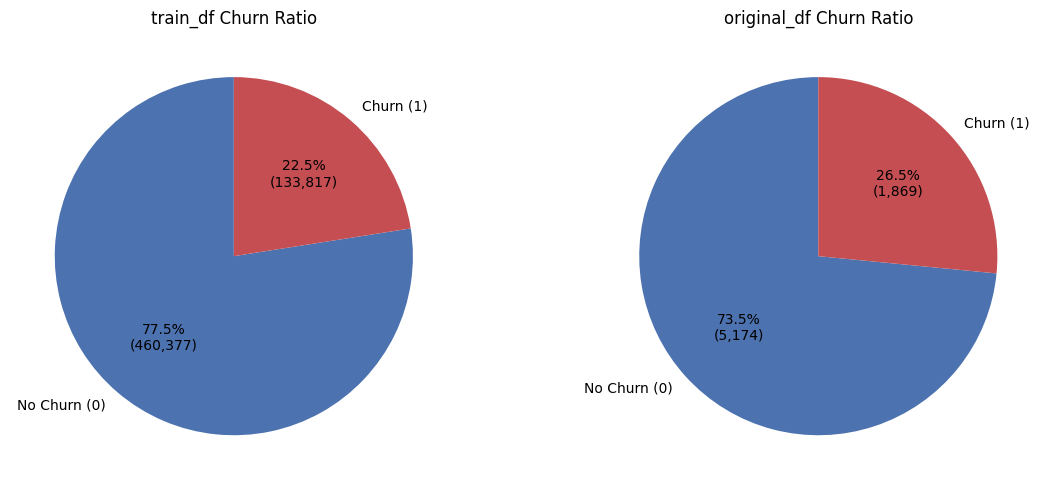

In [12]:
import matplotlib.pyplot as plt


def fmt_count_and_pct(pct, total):
    """円グラフ内に件数とパーセンテージを同時に表示するためのフォーマット関数"""
    absolute = int(round(pct / 100.0 * total))
    return f"{pct:.1f}%\n({absolute:,})"


# グラフ描画領域の設定（1行2列）
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- train_df の円グラフ ---
train_counts = train_df["Churn"].value_counts()
train_total = len(train_df["Churn"])
axes[0].pie(
    train_counts,
    labels=["No Churn (0)", "Churn (1)"],
    autopct=lambda pct: fmt_count_and_pct(pct, train_total),
    startangle=90,
    colors=["#4c72b0", "#c44e52"],
)
axes[0].set_title("train_df Churn Ratio")

# --- original_df の円グラフ ---
orig_counts = original_df["Churn"].value_counts()
orig_total = len(original_df["Churn"])
axes[1].pie(
    orig_counts,
    labels=["No Churn (0)", "Churn (1)"],
    autopct=lambda pct: fmt_count_and_pct(pct, orig_total),
    startangle=90,
    colors=["#4c72b0", "#c44e52"],
)
axes[1].set_title("original_df Churn Ratio")

plt.tight_layout()
plt.show()

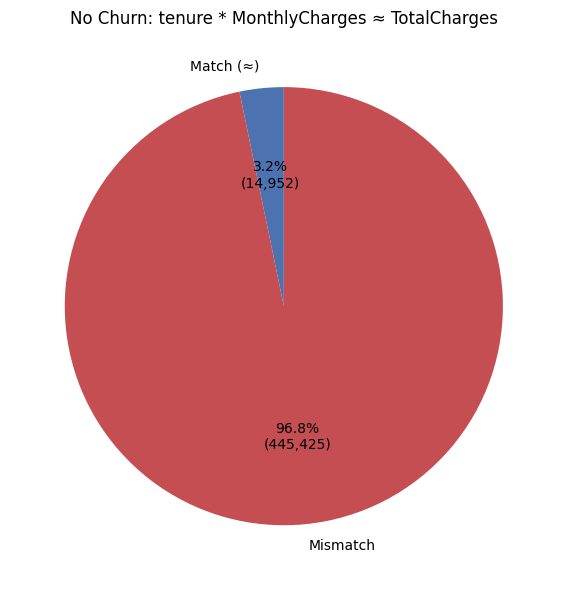

Match Ratio: 3.25%


In [13]:
# No Churn (Churn == 0) のデータを抽出
no_churn_df = train_df[train_df["Churn"] == 0].copy()

# tenure * MonthlyCharges と TotalCharges の計算および近似一致判定
calculated_total = no_churn_df["tenure"] * no_churn_df["MonthlyCharges"]
is_equal = np.isclose(
    calculated_total, no_churn_df["TotalCharges"], rtol=1e-3, atol=1e-2
)

# 一致・不一致の件数カウント
equal_counts = pd.Series(is_equal).value_counts()
match_count = equal_counts.get(True, 0)
mismatch_count = equal_counts.get(False, 0)
total_count = len(no_churn_df)


def fmt_count_and_pct(pct, total):
    """円グラフ内に件数とパーセンテージを同時に表示するためのフォーマット関数"""
    absolute = int(round(pct / 100.0 * total))
    return f"{pct:.1f}%\n({absolute:,})"


# 円グラフの描画
fig, ax = plt.subplots(figsize=(6, 6))

labels = ["Match (≈)", "Mismatch"]
sizes = [match_count, mismatch_count]
colors = ["#4c72b0", "#c44e52"]

ax.pie(
    sizes,
    labels=labels,
    autopct=lambda pct: fmt_count_and_pct(pct, total_count),
    startangle=90,
    colors=colors,
)
ax.set_title("No Churn: tenure * MonthlyCharges ≈ TotalCharges")

plt.tight_layout()
plt.show()

# 割合の出力
print(f"Match Ratio: {match_count / total_count * 100:.2f}%")

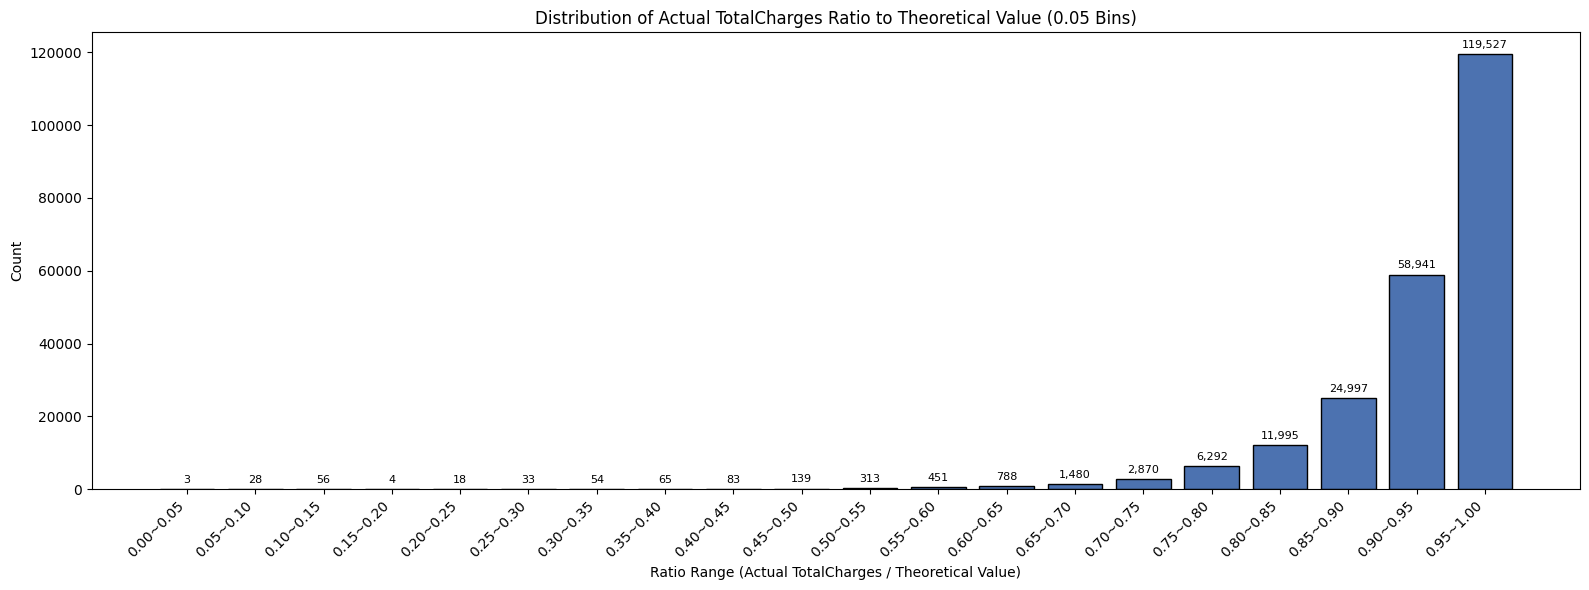

=== Filtered Ratio Statistics (0.00 - 1.00) ===
Target Samples: 228,137
Ratio Median (中間値): 0.9530
Ratio Mean   (平均値): 0.9311


In [14]:
# 1. No Churn データの抽出
no_churn_df = train_df[train_df["Churn"] == 0].copy()

# 2. 理論値の計算と一致判定
calculated_total = no_churn_df["tenure"] * no_churn_df["MonthlyCharges"]
is_equal = np.isclose(
    calculated_total, no_churn_df["TotalCharges"], rtol=1e-3, atol=1e-2
)

# 3. 一致しない（mismatch）データかつ tenure > 0 のデータを抽出
mismatch_df = no_churn_df[~is_equal & (no_churn_df["tenure"] > 0)].copy()

# 4. 理論値に対する実際の TotalCharges の比率を計算
ratio = (
    mismatch_df["TotalCharges"]
    / (mismatch_df["tenure"] * mismatch_df["MonthlyCharges"])
)

# 5. 比率が 0.00 〜 1.00 の範囲に含まれるデータを抽出
filtered_ratio = ratio[(ratio >= 0.0) & (ratio <= 1.00)]

# 6. 0.00 から 1.00 まで 0.05 刻みのビンを設定 (20区間)
bins = np.linspace(0.00, 1.00, 21)
bin_centers = (bins[:-1] + bins[1:]) / 2  # 棒を置く中央の位置

# 各区間の範囲ラベル文字列を作成 (例: "0.00~0.05", "0.05~0.10", ...)
bin_labels = [f"{bins[i]:.2f}~{bins[i+1]:.2f}" for i in range(len(bins) - 1)]

# 7. ビンごとの度数（件数）計算
counts, _ = np.histogram(filtered_ratio, bins=bins)

# 8. 棒グラフの描画
fig, ax = plt.subplots(figsize=(16, 6))

bars = ax.bar(
    bin_centers,
    counts,
    width=0.04,
    color="#4c72b0",
    edgecolor="black",
    align="center",
)

# 軸とタイトルの設定
ax.set_xlabel("Ratio Range (Actual TotalCharges / Theoretical Value)")
ax.set_ylabel("Count")
ax.set_title(
    "Distribution of Actual TotalCharges Ratio to Theoretical Value (0.05 Bins)"
)

# X軸の目盛り位置と範囲ラベル（小数点第2位まで表記）を設定
ax.set_xticks(bin_centers)
ax.set_xticklabels(bin_labels, rotation=45, ha="right")

# 各バーの上に件数を表示
for bar, count in zip(bars, counts):
    if count > 0:
        ax.annotate(
            f"{count:,}",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.tight_layout()
plt.show()

# 統計量の表示
median_val = filtered_ratio.median()
mean_val = filtered_ratio.mean()
print("=== Filtered Ratio Statistics (0.00 - 1.00) ===")
print(f"Target Samples: {len(filtered_ratio):,}")
print(f"Ratio Median (中間値): {median_val:.4f}")
print(f"Ratio Mean   (平均値): {mean_val:.4f}")

In [15]:
# 1. 補填に使用する中間値（median_val）の再計算・定義
no_churn_df = train_df[train_df["Churn"] == 0].copy()
calculated_total = no_churn_df["tenure"] * no_churn_df["MonthlyCharges"]
is_equal = np.isclose(
    calculated_total, no_churn_df["TotalCharges"], rtol=1e-3, atol=1e-2
)

mismatch_df = no_churn_df[~is_equal & (no_churn_df["tenure"] > 0)].copy()
ratio = (
    mismatch_df["TotalCharges"]
    / (mismatch_df["tenure"] * mismatch_df["MonthlyCharges"])
)
filtered_ratio = ratio[(ratio >= 0.0) & (ratio <= 1.00)]
median_val = filtered_ratio.median()

# 2. original_df の TotalCharges 欠損箇所を補填
missing_mask = original_df["TotalCharges"].isnull()
original_df.loc[missing_mask, "TotalCharges"] = median_val * (
    original_df.loc[missing_mask, "tenure"]
    * original_df.loc[missing_mask, "MonthlyCharges"]
)

# 3. 補填結果の確認
print(f"補填に使用した中間値 (median_val): {median_val:.4f}")
print(
    "original_df['TotalCharges'] null count after imputation:",
    original_df["TotalCharges"].isnull().sum(),
)

補填に使用した中間値 (median_val): 0.9530
original_df['TotalCharges'] null count after imputation: 0


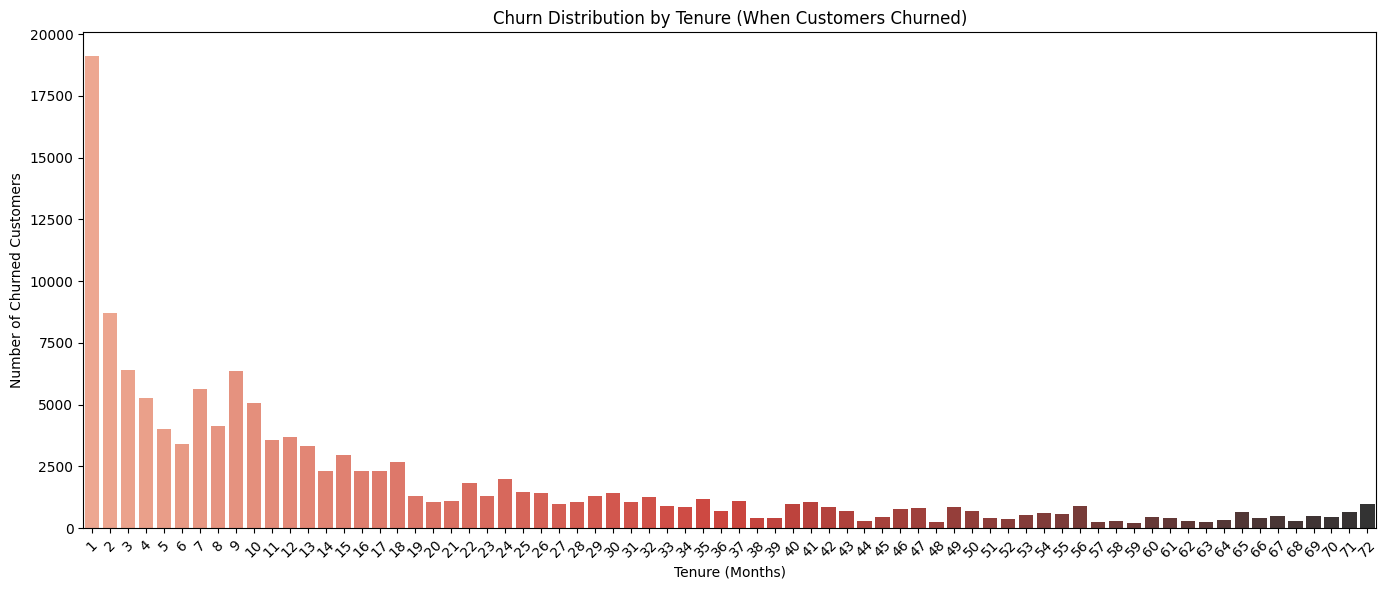

In [16]:
import seaborn as sns

# 1. train_df から Churn == 1（離脱者）のデータを抽出
churn_df = train_df[train_df["Churn"] == 1].copy()

# 2. tenure（月数）ごとの離脱者数を集計
tenure_churn_counts = (
    churn_df.groupby("tenure").size().reset_index(name="churn_count")
)

# 3. tenure 分布の棒グラフによる可視化（いつ離脱したかを確認）
plt.figure(figsize=(14, 6))
sns.barplot(
    data=tenure_churn_counts,
    x="tenure",
    y="churn_count",
    hue="tenure",
    palette="Reds_d",
    legend=False,
)

plt.title("Churn Distribution by Tenure (When Customers Churned)")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Churned Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

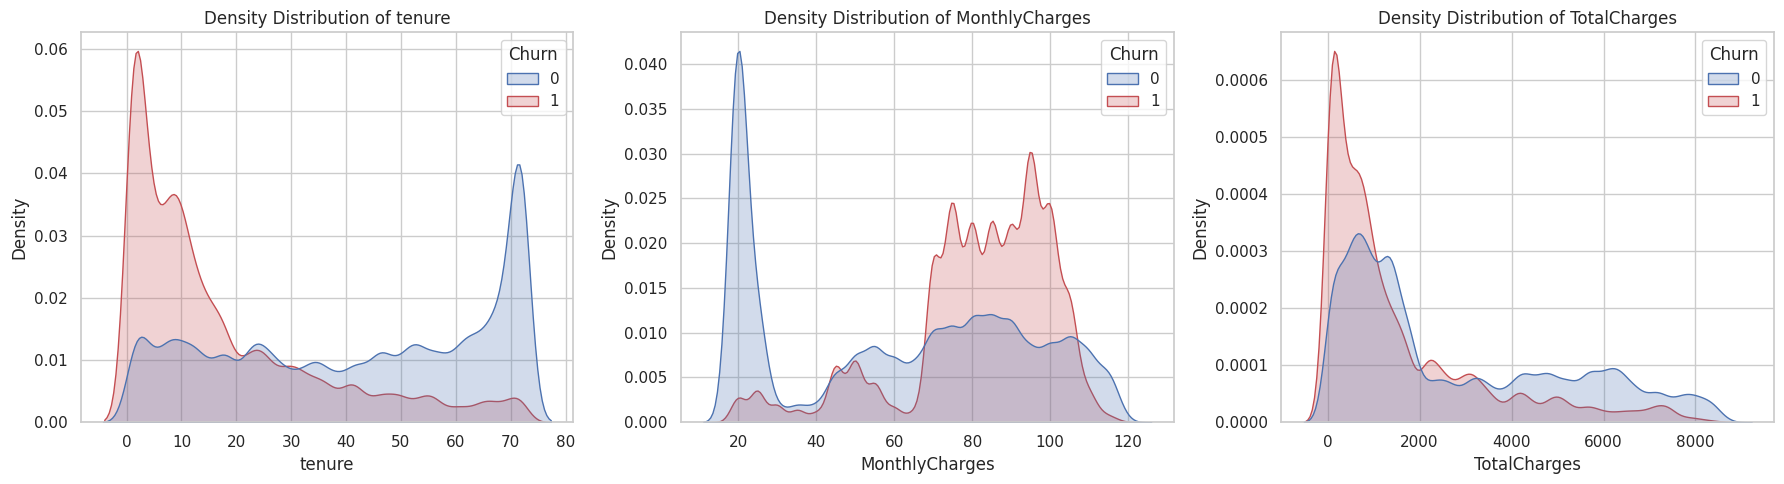

In [17]:
# 描画スタイルの設定
sns.set_theme(style="whitegrid")

# 1行3列のグラフ領域を作成
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 描画対象のカラムリスト
features = ["tenure", "MonthlyCharges", "TotalCharges"]

# 各特徴量の確率密度関数 (KDE) を Churn 別に描画
for i, feature in enumerate(features):
    sns.kdeplot(
        data=train_df,
        x=feature,
        hue="Churn",
        common_norm=False,  # 各グループごとに正規化して密度を表示
        shade=True,
        palette=["#4c72b0", "#c44e52"],
        ax=axes[i],
    )
    axes[i].set_title(f"Density Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Density")

plt.tight_layout()
plt.show()

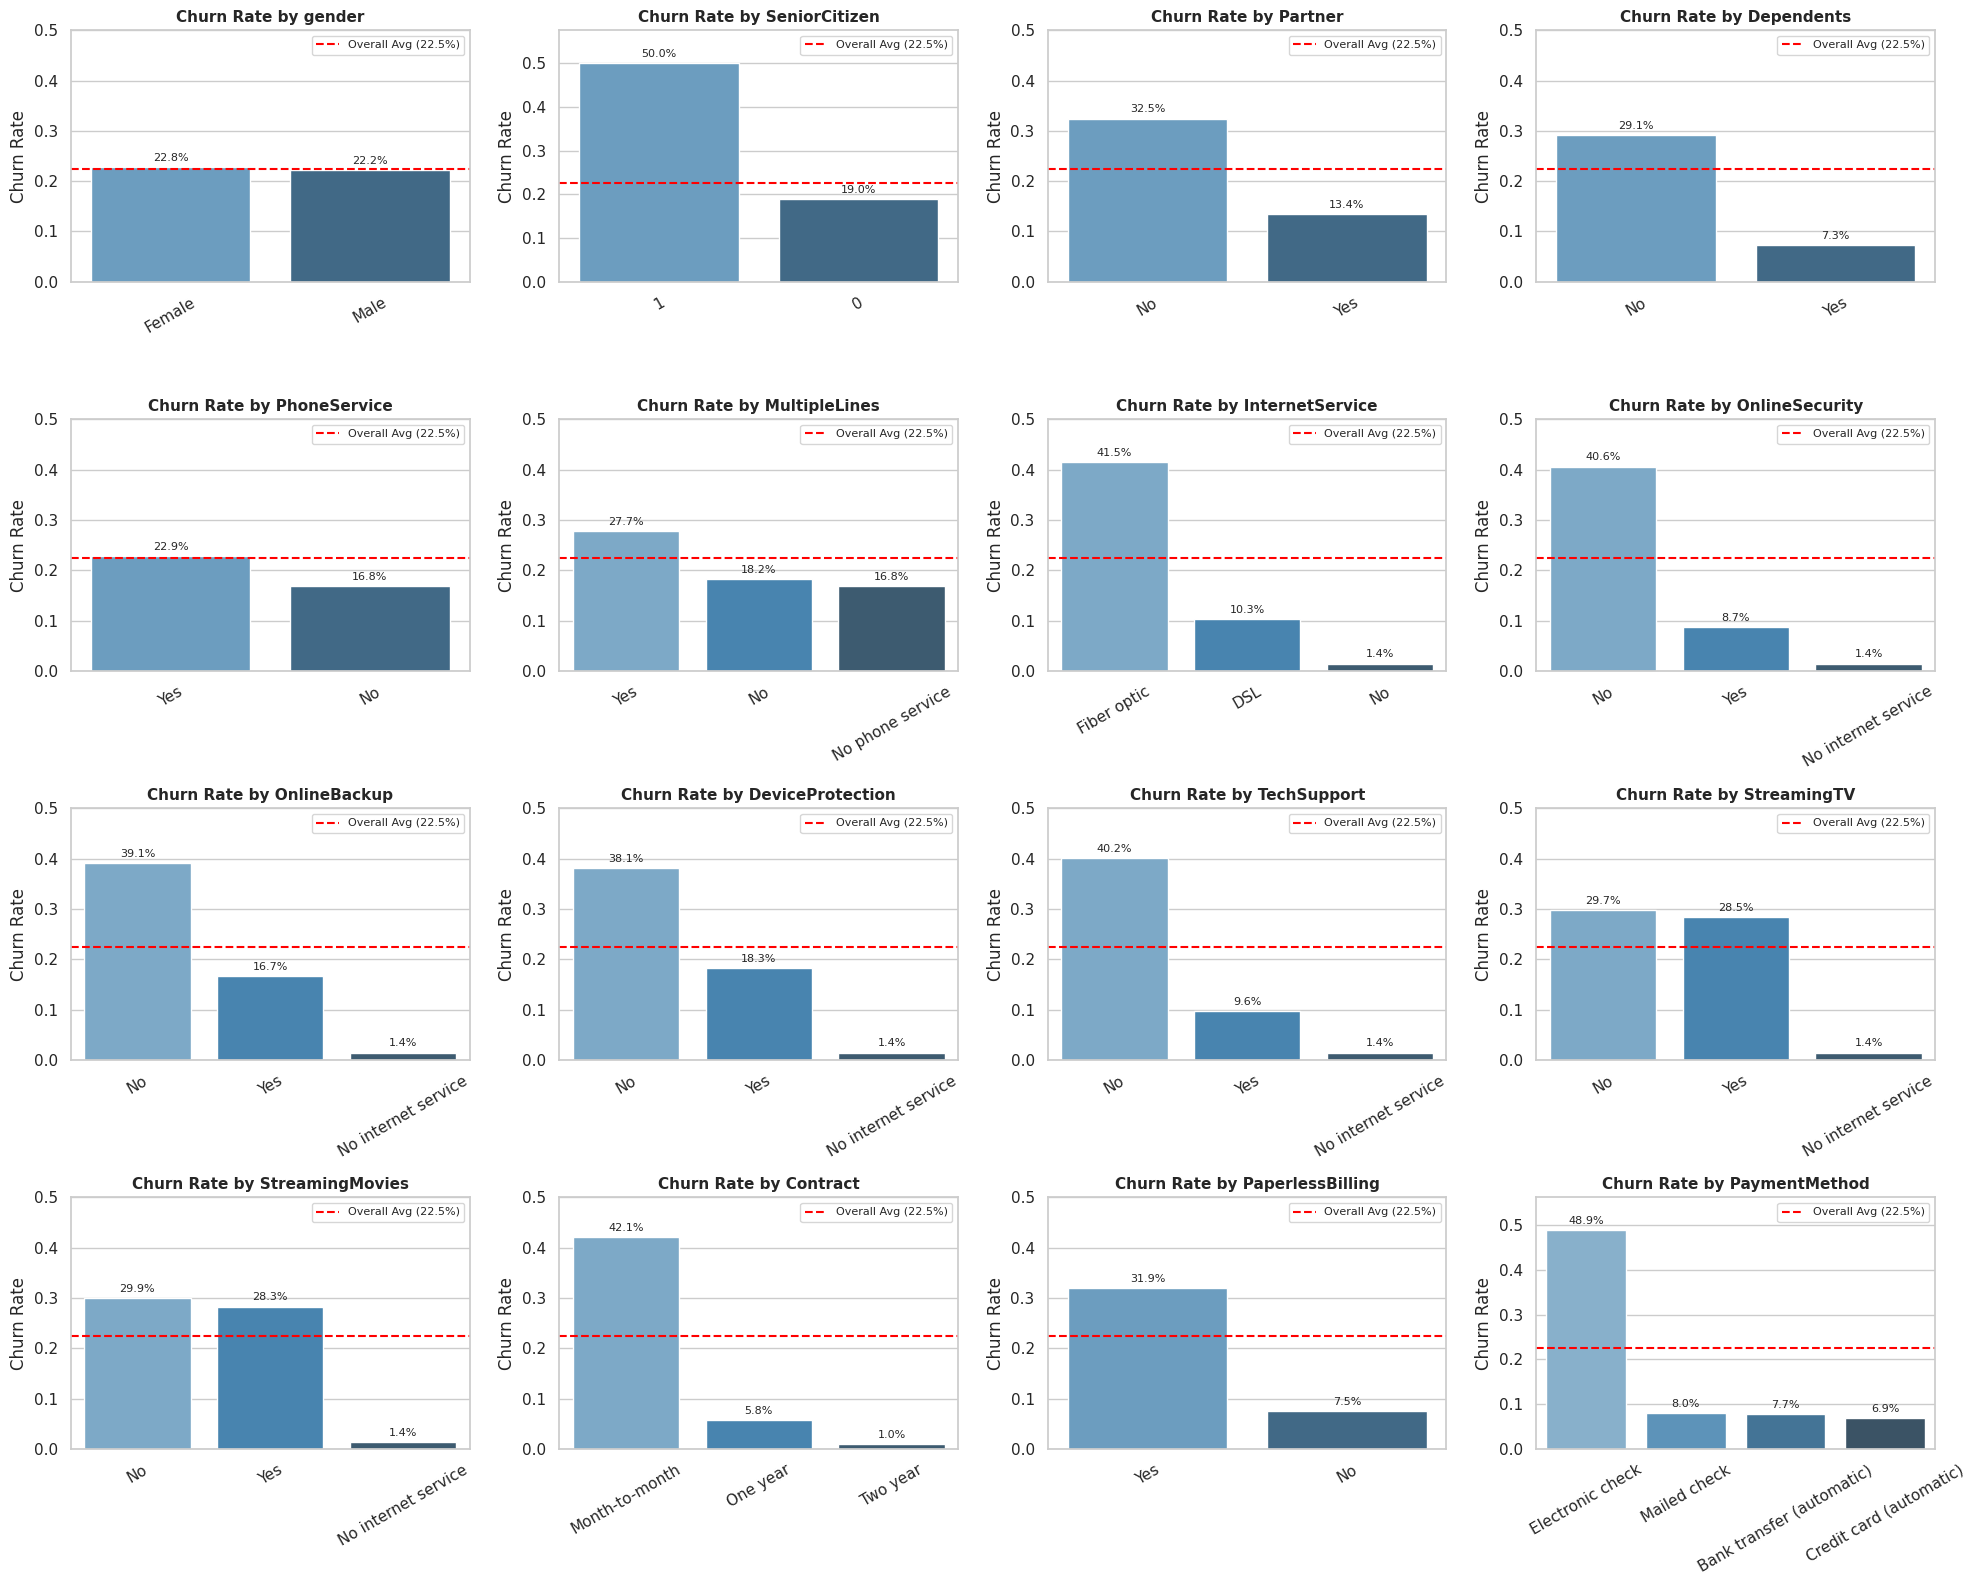

In [18]:
# 1. 16個のカテゴリカル変数を特定（数値列・id・Churnを除外）
exclude_cols = ["id", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
cat_cols = [col for col in train_df.columns if col not in exclude_cols]

# カテゴリカル変数が16個であることを確認（先頭16個を取得）
cat_cols = cat_cols[:16]

# 全体の平均離脱率を算出
overall_churn_rate = train_df["Churn"].mean()

# 2. 4行4列のグラフ描画領域を作成
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

# 3. 各カテゴリカル変数ごとに離脱率を降順ソートして描画
for i, col in enumerate(cat_cols):
    ax = axes[i]

    # カテゴリごとの離脱率を集計し、離脱率の降順にソート
    churn_by_cat = (
        train_df.groupby(col)["Churn"]
        .mean()
        .reset_index()
        .sort_values(by="Churn", ascending=False)
    )

    # 棒グラフの描画（orderパラメータでソート順を指定）
    sns.barplot(
        data=churn_by_cat,
        x=col,
        y="Churn",
        ax=ax,
        order=churn_by_cat[col],
        palette="Blues_d",
    )

    # 全体平均離脱率の点線を描画
    ax.axhline(
        overall_churn_rate,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Overall Avg ({overall_churn_rate:.1%})",
    )

    # タイトルと軸ラベルの設定
    ax.set_title(f"Churn Rate by {col}", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Churn Rate")
    ax.set_ylim(0, max(churn_by_cat["Churn"].max() * 1.15, 0.5))
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="upper right", fontsize=8)

    # 各バーの上に離脱率（%）を表示
    for p in ax.patches:
        height = p.get_height()
        if not np.isnan(height) and height > 0:
            ax.annotate(
                f"{height:.1%}",
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
            )

plt.tight_layout()
plt.show()

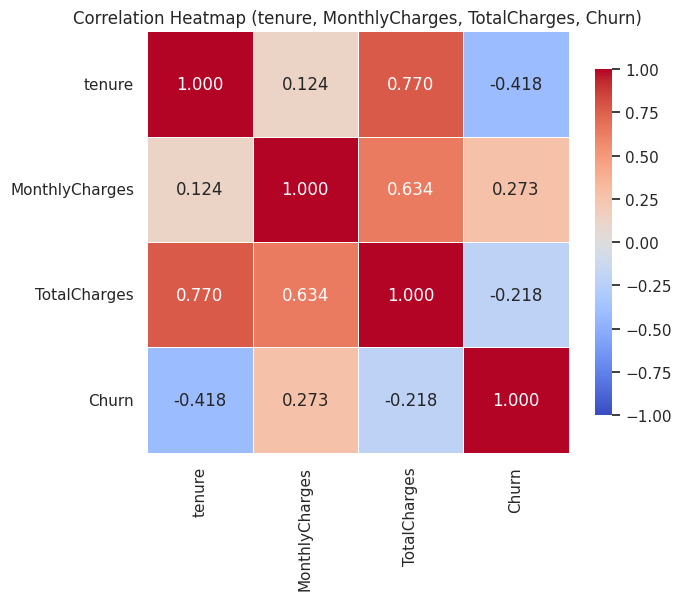

In [19]:
# 相関分析対象のカラムを設定
target_cols = ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]

# 相関係数行列の計算
corr = train_df[target_cols].corr()

# ヒートマップの描画
plt.figure(figsize=(7, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)

plt.title("Correlation Heatmap (tenure, MonthlyCharges, TotalCharges, Churn)")
plt.tight_layout()
plt.show()

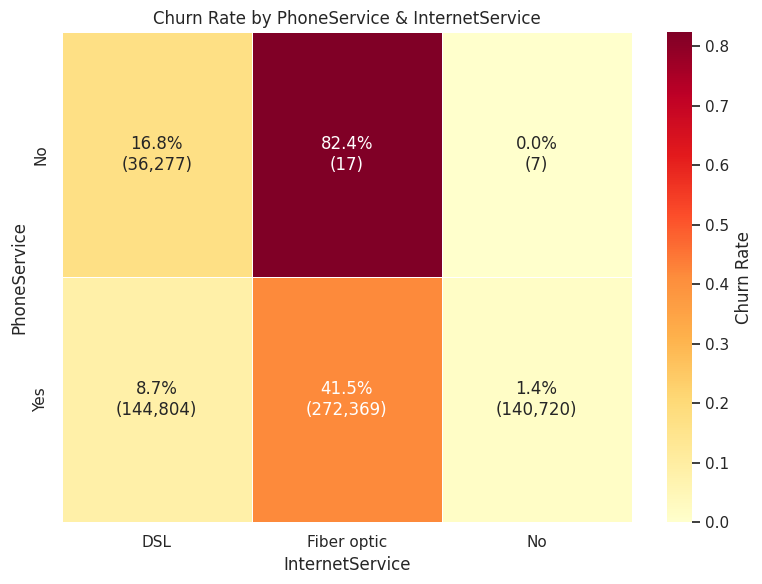

=== Churn Rate Table ===


InternetService,DSL,Fiber optic,No
PhoneService,,,
No,16.8%,82.4%,0.0%
Yes,8.7%,41.5%,1.4%


In [20]:
# 1. PhoneService と InternetService のクロス集計（離脱率と件数）
churn_pivot = train_df.pivot_table(
    index="PhoneService", columns="InternetService", values="Churn", aggfunc="mean"
)

count_pivot = train_df.pivot_table(
    index="PhoneService", columns="InternetService", values="Churn", aggfunc="count"
)

# 2. ヒートマップ内に表示するラベル文字列（離脱率 % と 件数）を作成
annot_labels = np.empty(churn_pivot.shape, dtype=object)
for i in range(churn_pivot.shape[0]):
    for j in range(churn_pivot.shape[1]):
        rate = churn_pivot.iloc[i, j]
        count = count_pivot.iloc[i, j]
        annot_labels[i, j] = f"{rate:.1%}\n({count:,})"

# 3. ヒートマップの描画
plt.figure(figsize=(8, 6))
sns.heatmap(
    churn_pivot,
    annot=annot_labels,
    fmt="",
    cmap="YlOrRd",
    cbar_kws={"label": "Churn Rate"},
    linewidths=0.5,
)

plt.title("Churn Rate by PhoneService & InternetService")
plt.xlabel("InternetService")
plt.ylabel("PhoneService")
plt.tight_layout()
plt.show()

# 4. 数値データのテーブル表示
print("=== Churn Rate Table ===")
display(churn_pivot.map(lambda x: f"{x:.1%}"))

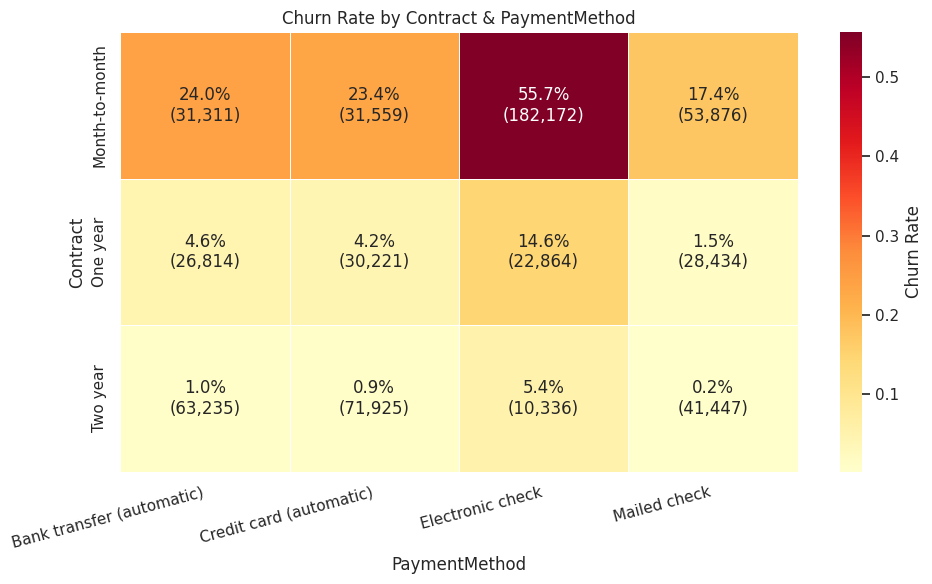

=== Churn Rate Table ===


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Contract,,,,
Month-to-month,24.0%,23.4%,55.7%,17.4%
One year,4.6%,4.2%,14.6%,1.5%
Two year,1.0%,0.9%,5.4%,0.2%


In [21]:
# 1. Contract と PaymentMethod のクロス集計（離脱率と件数）
churn_pivot = train_df.pivot_table(
    index="Contract", columns="PaymentMethod", values="Churn", aggfunc="mean"
)

count_pivot = train_df.pivot_table(
    index="Contract", columns="PaymentMethod", values="Churn", aggfunc="count"
)

# 2. ヒートマップ内に表示するラベル文字列（離脱率 % と 件数）を作成
annot_labels = np.empty(churn_pivot.shape, dtype=object)
for i in range(churn_pivot.shape[0]):
    for j in range(churn_pivot.shape[1]):
        rate = churn_pivot.iloc[i, j]
        count = count_pivot.iloc[i, j]
        annot_labels[i, j] = f"{rate:.1%}\n({count:,})"

# 3. ヒートマップの描画
plt.figure(figsize=(10, 6))
sns.heatmap(
    churn_pivot,
    annot=annot_labels,
    fmt="",
    cmap="YlOrRd",
    cbar_kws={"label": "Churn Rate"},
    linewidths=0.5,
)

plt.title("Churn Rate by Contract & PaymentMethod")
plt.xlabel("PaymentMethod")
plt.ylabel("Contract")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

# 4. 数値データのテーブル表示
print("=== Churn Rate Table ===")
display(churn_pivot.map(lambda x: f"{x:.1%}"))

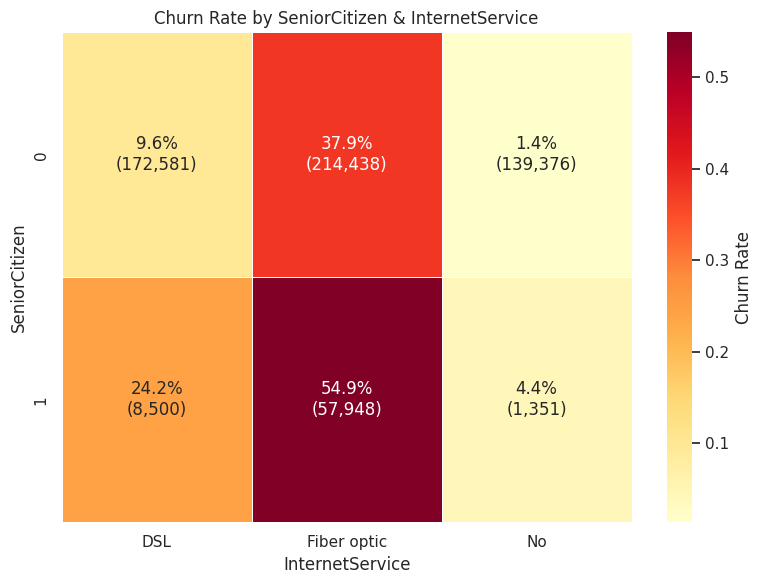

=== Churn Rate Table ===


InternetService,DSL,Fiber optic,No
SeniorCitizen,,,
0,9.6%,37.9%,1.4%
1,24.2%,54.9%,4.4%


In [22]:
# 1. SeniorCitizen と InternetService のクロス集計（離脱率と件数）
churn_pivot = train_df.pivot_table(
    index="SeniorCitizen",
    columns="InternetService",
    values="Churn",
    aggfunc="mean",
)

count_pivot = train_df.pivot_table(
    index="SeniorCitizen",
    columns="InternetService",
    values="Churn",
    aggfunc="count",
)

# 2. ヒートマップ内に表示するラベル文字列（離脱率 % と 件数）を作成
annot_labels = np.empty(churn_pivot.shape, dtype=object)
for i in range(churn_pivot.shape[0]):
    for j in range(churn_pivot.shape[1]):
        rate = churn_pivot.iloc[i, j]
        count = count_pivot.iloc[i, j]
        annot_labels[i, j] = f"{rate:.1%}\n({count:,})"

# 3. ヒートマップの描画
plt.figure(figsize=(8, 6))
sns.heatmap(
    churn_pivot,
    annot=annot_labels,
    fmt="",
    cmap="YlOrRd",
    cbar_kws={"label": "Churn Rate"},
    linewidths=0.5,
)

plt.title("Churn Rate by SeniorCitizen & InternetService")
plt.xlabel("InternetService")
plt.ylabel("SeniorCitizen")
plt.tight_layout()
plt.show()

# 4. 数値データのテーブル表示
print("=== Churn Rate Table ===")
display(churn_pivot.map(lambda x: f"{x:.1%}"))

In [23]:
# 1. train_dfの全16個のカテゴリカル変数
exclude_cols = ["id", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
categorical_cols = [
    col for col in train_df.columns if col not in exclude_cols
][:16]

# 2. tenure, MonthlyCharges, TotalChargesの数値変数
numerical_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# 3. 空リスト①（新規特徴量作成時の格納用）
new_features = []

# 4. 空リスト②（ビン化した特徴量の格納用）
binned_features = []

# 定義の確認用出力
print(f"Categorical Columns ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical Columns ({len(numerical_cols)}): {numerical_cols}")
print(f"New Features List: {new_features}")
print(f"Binned Features List: {binned_features}")

Categorical Columns (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical Columns (3): ['tenure', 'MonthlyCharges', 'TotalCharges']
New Features List: []
Binned Features List: []


In [24]:
# 1. データの連結（インデックスの保持や元の識別のためコピーを作成）
# train_df, test_df, original_df を結合して全データの出現頻度を算出します
# ここでは全16個のカテゴリカル変数に対して頻度エンコーディングを行う例とします
all_df = pd.concat([train_df, test_df, original_df], axis=0).reset_index(
    drop=True
)

# 2. カテゴリカル変数ごとに出現頻度を計算して新しいカラムを作成し、空リスト① (new_features) に追加する
for col in categorical_cols:
    freq_col_name = f"{col}_freq"

    # 全データでの出現回数（カウント）または割合を算出
    freq_map = all_df[col].value_counts().to_dict()

    # 各データフレームにマッピング
    train_df[freq_col_name] = train_df[col].map(freq_map)
    test_df[freq_col_name] = test_df[col].map(freq_map)
    original_df[freq_col_name] = original_df[col].map(freq_map)

    # 欠損値がある場合は 0 で補填し、float32 型に変換
    train_df[freq_col_name] = (
        train_df[freq_col_name].fillna(0).astype("float32")
    )
    test_df[freq_col_name] = test_df[freq_col_name].fillna(0).astype("float32")
    original_df[freq_col_name] = (
        original_df[freq_col_name].fillna(0).astype("float32")
    )

    # 空リスト① (new_features) に列名を追加（重複追加を防ぐ）
    if freq_col_name not in new_features:
        new_features.append(freq_col_name)

# 完了確認の出力
print(f"Added new frequency features to new_features list:")
for f in new_features:
    print(f"- {f}")

Added new frequency features to new_features list:
- gender_freq
- SeniorCitizen_freq
- Partner_freq
- Dependents_freq
- PhoneService_freq
- MultipleLines_freq
- InternetService_freq
- OnlineSecurity_freq
- OnlineBackup_freq
- DeviceProtection_freq
- TechSupport_freq
- StreamingTV_freq
- StreamingMovies_freq
- Contract_freq
- PaperlessBilling_freq
- PaymentMethod_freq


In [25]:
# 対象とするデータフレームのリスト
dfs = [train_df, test_df, original_df]

for df in dfs:
    # 1. 実効平均月額料金 (TotalCharges / tenure) の作成
    # tenure が 0 のケースでのゼロ除算（ZeroDivisionError / Inf）を防ぐため np.where を使用
    df["effective_monthly_charges"] = np.where(
        df["tenure"] > 0, df["TotalCharges"] / df["tenure"], 0.0
    ).astype("float32")

    # 2. 理論・推定基準の月額料金 (median_val * MonthlyCharges) の作成
    # ※ median_val はこれまでの処理で算出された値を使用します
    df["estimated_baseline_charges"] = (
        median_val * df["MonthlyCharges"]
    ).astype("float32")

# 3. 新規作成した列名を new_features リストに追加（重複を防ぐ）
feature_names = ["effective_monthly_charges", "estimated_baseline_charges"]
for fname in feature_names:
    if fname not in new_features:
        new_features.append(fname)

# 完了確認の出力
print(f"Updated new_features list: {new_features}")

Updated new_features list: ['gender_freq', 'SeniorCitizen_freq', 'Partner_freq', 'Dependents_freq', 'PhoneService_freq', 'MultipleLines_freq', 'InternetService_freq', 'OnlineSecurity_freq', 'OnlineBackup_freq', 'DeviceProtection_freq', 'TechSupport_freq', 'StreamingTV_freq', 'StreamingMovies_freq', 'Contract_freq', 'PaperlessBilling_freq', 'PaymentMethod_freq', 'effective_monthly_charges', 'estimated_baseline_charges']


In [26]:
# 対象とするデータフレームのリスト
dfs = [train_df, test_df, original_df]

for df in dfs:
    # 1. InternetService が Fiber optic かどうかを判定するフラグ
    # ※元のデータの表記が "Fiber optic" である前提で判定しています
    df["is_fiber_optic"] = (df["InternetService"] == "Fiber optic").astype(
        "float32"
    )

    # 2. PhoneService を契約しているかどうかを判定するフラグ
    # ※元のデータの表記が "Yes" である前提で判定しています
    df["has_phone_service"] = (df["PhoneService"] == "Yes").astype("float32")

# 3. 新規作成した列名を new_features リストに追加（重複を防ぐ）
feature_names = ["is_fiber_optic", "has_phone_service"]
for fname in feature_names:
    if fname not in new_features:
        new_features.append(fname)

# 完了確認の出力
print(f"Updated new_features list: {new_features}")

Updated new_features list: ['gender_freq', 'SeniorCitizen_freq', 'Partner_freq', 'Dependents_freq', 'PhoneService_freq', 'MultipleLines_freq', 'InternetService_freq', 'OnlineSecurity_freq', 'OnlineBackup_freq', 'DeviceProtection_freq', 'TechSupport_freq', 'StreamingTV_freq', 'StreamingMovies_freq', 'Contract_freq', 'PaperlessBilling_freq', 'PaymentMethod_freq', 'effective_monthly_charges', 'estimated_baseline_charges', 'is_fiber_optic', 'has_phone_service']


In [27]:
# 1. カテゴリカル変数ごとの離脱率
# （ターゲットエンコーディング）の算出とマッピング
for col in categorical_cols:
    target_col_name = f"{col}_target_enc"

    # train_df から各カテゴリの平均離脱率を算出
    encoding_map = train_df.groupby(col)["Churn"].mean().to_dict()

    # original_df にマッピング
    original_df[target_col_name] = original_df[col].map(encoding_map)

    # 未知の値（NaN）には中立的な確率 0.5 を補完
    # float32型に変換
    original_df[target_col_name] = (
        original_df[target_col_name].fillna(0.5).astype("float32")
    )

    # 新規特徴量リストへ追加
    if target_col_name not in new_features:
        new_features.append(target_col_name)


# 2. 数値変数（tenure, MonthlyCharges, TotalCharges）の
# ビン化・離脱率マッピング
# ※ ここでは例として qcut を用いて10分割のビンを作成

for col in numerical_cols:
    bin_col_name = f"{col}_bin"
    target_col_name = f"{col}_bin_target_enc"

    # train_df を基準にビンを分割
    train_bins, bin_edges = pd.qcut(
        train_df[col],
        q=10,
        retbins=True,
        duplicates="drop",
    )

    # train_df におけるビンごとの平均離脱率を算出
    train_df_temp = train_df.copy()
    train_df_temp[bin_col_name] = pd.cut(
        train_df_temp[col],
        bins=bin_edges,
        include_lowest=True,
    )
    bin_encoding_map = (
        train_df_temp.groupby(bin_col_name)["Churn"]
        .mean()
        .to_dict()
    )

    # original_df を同じビンに分割
    original_bins = pd.cut(
        original_df[col],
        bins=bin_edges,
        include_lowest=True,
    )

    # map 適用前に Series を object 型に変換
    # Categorical による制限を回避
    original_df[target_col_name] = (
        original_bins.astype(object).map(bin_encoding_map)
    )

    # 未知の値や範囲外（NaN）には 0.5 を補完
    # float32型に変換
    original_df[target_col_name] = (
        original_df[target_col_name].fillna(0.5).astype("float32")
    )

    # 新規特徴量リストへ追加
    if target_col_name not in new_features:
        new_features.append(target_col_name)

# 完了確認の出力
print("Updated new_features list with target encodings:")
for f in new_features:
    print(f"- {f}")

Updated new_features list with target encodings:
- gender_freq
- SeniorCitizen_freq
- Partner_freq
- Dependents_freq
- PhoneService_freq
- MultipleLines_freq
- InternetService_freq
- OnlineSecurity_freq
- OnlineBackup_freq
- DeviceProtection_freq
- TechSupport_freq
- StreamingTV_freq
- StreamingMovies_freq
- Contract_freq
- PaperlessBilling_freq
- PaymentMethod_freq
- effective_monthly_charges
- estimated_baseline_charges
- is_fiber_optic
- has_phone_service
- gender_target_enc
- SeniorCitizen_target_enc
- Partner_target_enc
- Dependents_target_enc
- PhoneService_target_enc
- MultipleLines_target_enc
- InternetService_target_enc
- OnlineSecurity_target_enc
- OnlineBackup_target_enc
- DeviceProtection_target_enc
- TechSupport_target_enc
- StreamingTV_target_enc
- StreamingMovies_target_enc
- Contract_target_enc
- PaperlessBilling_target_enc
- PaymentMethod_target_enc
- tenure_bin_target_enc
- MonthlyCharges_bin_target_enc
- TotalCharges_bin_target_enc


In [28]:
# 1. 二分探索を用いたパーセンタイルランク算出
def pctrank_against(values, reference_array):
    """二分探索 (np.searchsorted) を用いて

    参照配列における値のパーセンタイルランクを計算します。
    """
    sorted_ref = np.sort(reference_array)
    n = len(sorted_ref)

    if n == 0:
        return np.zeros_like(values, dtype=float)

    insert_indices = np.searchsorted(sorted_ref, values, side="right")
    return insert_indices / n


# 2. 離脱者・継続者分布との距離計算
train_churn = train_df[train_df["Churn"] == 1]["TotalCharges"].dropna()
train_non_churn = train_df[train_df["Churn"] == 0]["TotalCharges"].dropna()

median_churn = train_churn.median()
median_non_churn = train_non_churn.median()

for df in [train_df, test_df, original_df]:
    tc = df["TotalCharges"].fillna(df["TotalCharges"].median())

    dist_to_churn = np.abs(tc - median_churn)
    dist_to_non_churn = np.abs(tc - median_non_churn)

    df["total_charges_churn_distance_diff"] = (
        dist_to_non_churn - dist_to_churn
    ).astype("float32")

    if "total_charges_churn_distance_diff" not in new_features:
        new_features.append("total_charges_churn_distance_diff")


# 3. 条件付きパーセンタイルランクの算出
def add_conditional_pctrank(
    df_target, df_ref, group_col, value_col, new_col_name
):
    """グループごとの条件付きパーセンタイルランクを算出します。"""
    ranks = []
    for val, group in df_target.groupby(group_col):
        ref_group_values = df_ref[df_ref[group_col] == val][
            value_col
        ].values
        target_values = group[value_col].values

        pct_ranks = pctrank_against(target_values, ref_group_values)

        temp_df = pd.DataFrame(
            {new_col_name: pct_ranks},
            index=group.index,
        )
        ranks.append(temp_df)

    res_df = pd.concat(ranks).sort_index()
    return res_df[new_col_name].astype("float32")


# Contract ごとの MonthlyCharges の条件付きランク
for df in [train_df, test_df, original_df]:
    col_name = "monthly_charges_pct_by_contract"
    df[col_name] = add_conditional_pctrank(
        df_target=df,
        df_ref=train_df,
        group_col="Contract",
        value_col="MonthlyCharges",
        new_col_name=col_name,
    )
    if col_name not in new_features:
        new_features.append(col_name)

# PaymentMethod ごとの tenure の条件付きランク
for df in [train_df, test_df, original_df]:
    col_name = "tenure_pct_by_payment"
    df[col_name] = add_conditional_pctrank(
        df_target=df,
        df_ref=train_df,
        group_col="PaymentMethod",
        value_col="tenure",
        new_col_name=col_name,
    )
    if col_name not in new_features:
        new_features.append(col_name)

# 完了確認の出力
print("Updated new_features list with advanced ranking features:")
for f in new_features:
    print(f"- {f}")

Updated new_features list with advanced ranking features:
- gender_freq
- SeniorCitizen_freq
- Partner_freq
- Dependents_freq
- PhoneService_freq
- MultipleLines_freq
- InternetService_freq
- OnlineSecurity_freq
- OnlineBackup_freq
- DeviceProtection_freq
- TechSupport_freq
- StreamingTV_freq
- StreamingMovies_freq
- Contract_freq
- PaperlessBilling_freq
- PaymentMethod_freq
- effective_monthly_charges
- estimated_baseline_charges
- is_fiber_optic
- has_phone_service
- gender_target_enc
- SeniorCitizen_target_enc
- Partner_target_enc
- Dependents_target_enc
- PhoneService_target_enc
- MultipleLines_target_enc
- InternetService_target_enc
- OnlineSecurity_target_enc
- OnlineBackup_target_enc
- DeviceProtection_target_enc
- TechSupport_target_enc
- StreamingTV_target_enc
- StreamingMovies_target_enc
- Contract_target_enc
- PaperlessBilling_target_enc
- PaymentMethod_target_enc
- tenure_bin_target_enc
- MonthlyCharges_bin_target_enc
- TotalCharges_bin_target_enc
- total_charges_churn_dist

In [29]:
# 1. train_df から 離脱者(Churn=1) と 継続者(Churn=0) の TotalCharges の四分位数を算出
train_churn = train_df[train_df["Churn"] == 1]["TotalCharges"].dropna()
train_non_churn = train_df[train_df["Churn"] == 0]["TotalCharges"].dropna()

# 離脱者の統計量
q1_churn, med_churn, q3_churn = np.percentile(train_churn, [25, 50, 75])

# 継続者の統計量
q1_non_churn, med_non_churn, q3_non_churn = np.percentile(
    train_non_churn, [25, 50, 75]
)

# 2. original_df に対する四分位数ベースの距離と差分の計算
for df in [original_df]:
    tc = df["TotalCharges"].fillna(df["TotalCharges"].median())

    # 中央値からの絶対距離
    dist_med_churn = np.abs(tc - med_churn)
    dist_med_non_churn = np.abs(tc - med_non_churn)

    # どちらの中央値に近いかの差分（継続者中央値からの距離 - 離脱者中央値からの距離）
    # 正負の符号によって、どちらのグループの傾向に寄り添っているかを表現
    col_diff_med = "tc_median_distance_diff"
    df[col_diff_med] = (dist_med_non_churn - dist_med_churn).astype("float32")

    # 第1四分位 (Q1) および 第3四分位 (Q3) からの距離の差分特徴量も追加
    dist_q1_churn = np.abs(tc - q1_churn)
    dist_q1_non_churn = np.abs(tc - q1_non_churn)
    col_diff_q1 = "tc_q1_distance_diff"
    df[col_diff_q1] = (dist_q1_non_churn - dist_q1_churn).astype("float32")

    dist_q3_churn = np.abs(tc - q3_churn)
    dist_q3_non_churn = np.abs(tc - q3_non_churn)
    col_diff_q3 = "tc_q3_distance_diff"
    df[col_diff_q3] = (dist_q3_non_churn - dist_q3_churn).astype("float32")

    # 新規特徴量リストへ追加
    for c in [col_diff_med, col_diff_q1, col_diff_q3]:
        if c not in new_features:
            new_features.append(c)

# 完了確認の出力
print("Updated new_features list with quartile/median distance features:")
for f in new_features:
    print(f"- {f}")

Updated new_features list with quartile/median distance features:
- gender_freq
- SeniorCitizen_freq
- Partner_freq
- Dependents_freq
- PhoneService_freq
- MultipleLines_freq
- InternetService_freq
- OnlineSecurity_freq
- OnlineBackup_freq
- DeviceProtection_freq
- TechSupport_freq
- StreamingTV_freq
- StreamingMovies_freq
- Contract_freq
- PaperlessBilling_freq
- PaymentMethod_freq
- effective_monthly_charges
- estimated_baseline_charges
- is_fiber_optic
- has_phone_service
- gender_target_enc
- SeniorCitizen_target_enc
- Partner_target_enc
- Dependents_target_enc
- PhoneService_target_enc
- MultipleLines_target_enc
- InternetService_target_enc
- OnlineSecurity_target_enc
- OnlineBackup_target_enc
- DeviceProtection_target_enc
- TechSupport_target_enc
- StreamingTV_target_enc
- StreamingMovies_target_enc
- Contract_target_enc
- PaperlessBilling_target_enc
- PaymentMethod_target_enc
- tenure_bin_target_enc
- MonthlyCharges_bin_target_enc
- TotalCharges_bin_target_enc
- total_charges_ch

In [30]:
# 変換対象の数値変数
target_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
]

# train_df, test_df, original_df すべてに対して適用
dfs = [train_df, test_df, original_df]

for col in target_cols:
    for df in dfs:
        # 一度文字列に変換し、その後 category 型として再定義
        df[col] = df[col].astype(str).astype("category")

    # 管理用リスト② (binned_features) に列名を追加（重複を防ぐ）
    if col not in binned_features:
        binned_features.append(col)

# 完了確認の出力
print(f"Updated binned_features list: {binned_features}")

Updated binned_features list: ['tenure', 'MonthlyCharges', 'TotalCharges']


In [31]:
# 処理対象のデータフレームリスト
dfs = [train_df, test_df, original_df]

# 1. Bi-gram と Tri-gram の組み合わせに用いる主要なカテゴリカル変数の選択
# （例として、代表的なカテゴリカル列からいくつか、あるいは全16個から選択）
base_cols = categorical_cols[:4]  # 必要に応じて対象カラムを調整してください

for df in dfs:
    # 2. それぞれの結果を格納する空カラムの事前作成
    df["bigram_feature"] = ""
    df["trigram_feature"] = ""
    df["combined_ngram_feature"] = ""

# 3. Bi-gram（上位8カテゴリ）および Tri-gram（上位6カテゴリ）の作成関数・処理
# 頻出する上位カテゴリを抽出して合成する
for df in dfs:
    # --- Bi-gram の作成 (上位8カテゴリの組み合わせ) ---
    # 主要な2つのカラム（例: base_cols[0] と base_cols[1]）のトップ8カテゴリを抽出
    top_col0 = (
        train_df[base_cols[0]].value_counts().head(8).index.tolist()
    )
    top_col1 = (
        train_df[base_cols[1]].value_counts().head(8).index.tolist()
    )

    # 上位に含まれる場合はその値、それ以外は "Other" に置き換えて結合
    val0 = df[base_cols[0]].apply(lambda x: x if x in top_col0 else "Other")
    val1 = df[base_cols[1]].apply(lambda x: x if x in top_col1 else "Other")
    df["bigram_feature"] = val0.astype(str) + "_" + val1.astype(str)

    # --- Tri-gram の作成 (上位6カテゴリの組み合わせ) ---
    # 主要な3つのカラムのトップ6カテゴリを抽出
    top_t0 = (
        train_df[base_cols[0]].value_counts().head(6).index.tolist()
    )
    top_t1 = (
        train_df[base_cols[1]].value_counts().head(6).index.tolist()
    )
    top_t2 = (
        train_df[base_cols[2]].value_counts().head(6).index.tolist()
    )

    vt0 = df[base_cols[0]].apply(lambda x: x if x in top_t0 else "Other")
    vt1 = df[base_cols[1]].apply(lambda x: x if x in top_t1 else "Other")
    vt2 = df[base_cols[2]].apply(lambda x: x if x in top_t2 else "Other")
    df["trigram_feature"] = (
        vt0.astype(str) + "_" + vt1.astype(str) + "_" + vt2.astype(str)
    )

    # 4. Bi-gram と Tri-gram の特徴量を同一カラムに統合
    df["combined_ngram_feature"] = (
        df["bigram_feature"].astype(str)
        + "__"
        + df["trigram_feature"].astype(str)
    )

    # カテゴリ型へ変換
    df["bigram_feature"] = df["bigram_feature"].astype("category")
    df["trigram_feature"] = df["trigram_feature"].astype("category")
    df["combined_ngram_feature"] = df[
        "combined_ngram_feature"
    ].astype("category")

# 新規作成した統合特徴量などを管理用リストに追加
for col_name in ["bigram_feature", "trigram_feature", "combined_ngram_feature"]:
    if col_name not in new_features:
        new_features.append(col_name)

# 完了確認の出力
print("N-gram features successfully generated and combined.")
print(f"Updated new_features list: {new_features[-3:]}")

N-gram features successfully generated and combined.
Updated new_features list: ['bigram_feature', 'trigram_feature', 'combined_ngram_feature']


In [32]:
# 1. 全特徴量を網羅したリストの作成
# これまでに作成・定義された主要な特徴量やカラムをすべて統合します
all_features = list(
    set(
        categorical_cols
        + numerical_cols
        + new_features
        + binned_features
    )
)

# 2. 元のカテゴリカル変数と数値のカテゴリ化列の特徴量を格納したリスト
# （categorical_cols と binned_features を結合）
original_and_binned_categorical_features = list(
    set(categorical_cols + binned_features)
)

# 3. 先ほど生成した N-gram 合成カテゴリカル特徴量を格納したリスト
ngram_features = [
    "bigram_feature",
    "trigram_feature",
    "combined_ngram_feature",
]

# 4. 後者2つ（オリジナル/カテゴリ化列リスト と N-gramリスト）を統合したリスト
combined_categorical_ngram_features = list(
    set(original_and_binned_categorical_features + ngram_features)
)

# 完了確認の出力（PEP 8準拠）
print("--- Features Lists Created ---")
print(f"Total: {len(all_features)}")
print(
    "Orig & Binned Count:",
    len(original_and_binned_categorical_features),
)
print(f"N-gram Count: {len(ngram_features)}")
print(
    "Combined Count:",
    len(combined_categorical_ngram_features),
)

--- Features Lists Created ---
Total: 67
Orig & Binned Count: 19
N-gram Count: 3
Combined Count: 22


In [33]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.9 MB/s eta 0:00:00


In [34]:
import lightgbm as lgb
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb

# ==========================================
# 1. モデルの定義（CatBoostを含めた全6モデル）
# ==========================================
models = {
    "LogisticRegression": LogisticRegression(
        random_state=42, max_iter=1000
    ),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),
    "LightGBM": lgb.LGBMClassifier(random_state=42, verbose=-1),
    "XGBoost": xgb.XGBClassifier(random_state=42, eval_metric="logloss"),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=0),
}

# スケーリング（StandardScaler）が必要なモデルのリスト
scaling_required_models = {
    "LogisticRegression",
}


# ==========================================
# 2. ターゲットエンコーディング関数の定義
# ==========================================
def apply_target_encoding(
    train_fold, val_fold, cat_cols, target_col="Churn"
):
    """外側/内側のTrainデータからTEマップを計算し、TrainとValに適用します。"""
    tr_enc = train_fold.copy()
    va_enc = val_fold.copy()

    for col in cat_cols:
        target_name = f"{col}_te"

        tr_series = tr_enc[col].astype(str)
        va_series = va_enc[col].astype(str)

        encoding_map = (
            pd.DataFrame({col: tr_series, target_col: tr_enc[target_col]})
            .groupby(col)[target_col]
            .mean()
            .to_dict()
        )

        tr_mapped = (
            tr_series
            .map(encoding_map)
            .fillna(0.5)
            .astype("float32")
        )
        va_mapped = (
            va_series
            .map(encoding_map)
            .fillna(0.5)
            .astype("float32")
        )

        if target_name in tr_enc.columns:
            tr_enc = tr_enc.drop(columns=[target_name])
        if target_name in va_enc.columns:
            va_enc = va_enc.drop(columns=[target_name])

        tr_enc[target_name] = tr_mapped
        va_enc[target_name] = va_mapped

    return tr_enc, va_enc


# ==========================================
# 3. Nested CV ループの構築
# ==========================================
available_categorical = [
    c for c in categorical_cols if c in train_df.columns
]
available_ngram = [
    c for c in ngram_features if c in train_df.columns
]
cat_cols_to_encode = list(set(available_categorical + available_ngram))

base_features = [
    f for f in all_features
    if f not in ["Churn", "customerID"] and f in train_df.columns
]

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {name: [] for name in models.keys()}

print("--- Starting Nested CV Training ---")

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(train_df, train_df["Churn"])
):
    print(f"\n--- Outer Fold {fold + 1}/5 ---")

    outer_train = train_df.iloc[train_idx].copy()
    outer_val = train_df.iloc[val_idx].copy()

    # ★追加対策：エンコード対象外の列で category 型になっている数値列があれば安全に float に戻す
    for col in outer_train.columns:
        if outer_train[col].dtype.name == "category" and col not in cat_cols_to_encode:
            outer_train[col] = outer_train[col].astype("float32", errors="ignore")
            outer_val[col] = outer_val[col].astype("float32", errors="ignore")

    # 外側Train基準でターゲットエンコーディングを適用
    outer_train_enc, outer_val_enc = apply_target_encoding(
        outer_train, outer_val, cat_cols_to_encode
    )

    te_cols = [f"{c}_te" for c in cat_cols_to_encode]

    current_features = [
        f for f in base_features if f not in cat_cols_to_encode
    ] + te_cols

    current_features = [
        f for f in current_features if f in outer_train_enc.columns
    ]

    X_train = outer_train_enc[current_features]
    y_train = outer_train_enc["Churn"]
    X_val = outer_val_enc[current_features]
    y_val = outer_val_enc["Churn"]

    # 各モデルの学習と評価ループ
    for name, model in models.items():
        clf = clone(model)

        if name in scaling_required_models:
            scaler = StandardScaler()
            X_train_processed = scaler.fit_transform(X_train)
            X_val_processed = scaler.transform(X_val)
        else:
            X_train_processed = X_train
            X_val_processed = X_val

        clf.fit(X_train_processed, y_train)

        if hasattr(clf, "predict_proba"):
            preds = clf.predict_proba(X_val_processed)[:, 1]
        else:
            preds = clf.decision_function(X_val_processed)

        score = roc_auc_score(y_val, preds)
        cv_results[name].append(score)

# ==========================================
# 4. 結果の集計
# ==========================================
print("\n--- Outer CV Results (Mean ROC-AUC) ---")
for name, scores in cv_results.items():
    mean_score = np.mean(scores)
    std_score = np.std(scores)
    print(f"{name:20s}: {mean_score:.4f} (±{std_score:.4f})")

--- Starting Nested CV Training ---

--- Outer Fold 1/5 ---

--- Outer Fold 2/5 ---

--- Outer Fold 3/5 ---

--- Outer Fold 4/5 ---

--- Outer Fold 5/5 ---

--- Outer CV Results (Mean ROC-AUC) ---
LogisticRegression  : 0.9088 (±0.0010)
DecisionTree        : 0.7251 (±0.0018)
RandomForest        : 0.8983 (±0.0011)
LightGBM            : 0.9154 (±0.0009)
XGBoost             : 0.9155 (±0.0010)
CatBoost            : 0.9162 (±0.0010)


In [35]:
import lightgbm as lgb
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import (
    LogisticRegression,
    Perceptron,
    SGDClassifier,
)
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb

# ==========================================
# 1. モデルの定義（SVM・KNNを除外した10モデル）
# ==========================================
models = {
    "LogisticRegression": LogisticRegression(
        random_state=42, max_iter=1000
    ),
    "GaussianNB": GaussianNB(),
    "Perceptron": Perceptron(random_state=42),
    "LinearSVC": LinearSVC(random_state=42, max_iter=1000),
    "SGDClassifier": SGDClassifier(random_state=42),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),
    "LightGBM": lgb.LGBMClassifier(random_state=42, verbose=-1),
    "XGBoost": xgb.XGBClassifier(random_state=42, eval_metric="logloss"),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=0),
}

# スケーリング（StandardScaler）が必要な線形モデル等のリスト
scaling_required_models = {
    "LogisticRegression",
    "Perceptron",
    "LinearSVC",
    "SGDClassifier",
    "GaussianNB",
}


# ==========================================
# 2. ターゲットエンコーディング関数の定義
# ==========================================
def apply_target_encoding(
    train_fold, val_fold, cat_cols, target_col="Churn"
):
    """外側/内側のTrainデータからTEマップを計算し、TrainとValに適用します。"""
    tr_enc = train_fold.copy()
    va_enc = val_fold.copy()

    for col in cat_cols:
        target_name = f"{col}_te"

        tr_series = tr_enc[col].astype(str)
        va_series = va_enc[col].astype(str)

        encoding_map = (
            pd.DataFrame({col: tr_series, target_col: tr_enc[target_col]})
            .groupby(col)[target_col]
            .mean()
            .to_dict()
        )

        tr_mapped = (
            tr_series
            .map(encoding_map)
            .fillna(0.5)
            .astype("float32")
        )
        va_mapped = (
            va_series
            .map(encoding_map)
            .fillna(0.5)
            .astype("float32")
        )

        if target_name in tr_enc.columns:
            tr_enc = tr_enc.drop(columns=[target_name])
        if target_name in va_enc.columns:
            va_enc = va_enc.drop(columns=[target_name])

        tr_enc[target_name] = tr_mapped
        va_enc[target_name] = va_mapped

    return tr_enc, va_enc


# ==========================================
# 3. Nested CV ループの構築
# ==========================================
available_categorical = [
    c for c in categorical_cols if c in train_df.columns
]
available_ngram = [
    c for c in ngram_features if c in train_df.columns
]
cat_cols_to_encode = list(set(available_categorical + available_ngram))

base_features = [
    f for f in all_features
    if f not in ["Churn", "customerID"] and f in train_df.columns
]

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {name: [] for name in models.keys()}

print("--- Starting Nested CV Training (10 Models Baseline) ---", flush=True)

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(train_df, train_df["Churn"])
):
    print(f"\n--- Outer Fold {fold + 1}/5 ---", flush=True)

    outer_train = train_df.iloc[train_idx].copy()
    outer_val = train_df.iloc[val_idx].copy()

    # 安全な型キャスト処理（PEP-8準拠の折り返し）
    for col in outer_train.columns:
        is_category = outer_train[col].dtype.name == "category"
        is_not_encoded = col not in cat_cols_to_encode

        if is_category and is_not_encoded:
            outer_train[col] = outer_train[col].astype(
                "float32", errors="ignore"
            )
            outer_val[col] = outer_val[col].astype(
                "float32", errors="ignore"
            )

    # 外側Train基準でターゲットエンコーディングを適用
    outer_train_enc, outer_val_enc = apply_target_encoding(
        outer_train, outer_val, cat_cols_to_encode
    )

    te_cols = [f"{c}_te" for c in cat_cols_to_encode]

    current_features = [
        f for f in base_features if f not in cat_cols_to_encode
    ] + te_cols

    current_features = [
        f for f in current_features if f in outer_train_enc.columns
    ]

    X_train = outer_train_enc[current_features]
    y_train = outer_train_enc["Churn"]
    X_val = outer_val_enc[current_features]
    y_val = outer_val_enc["Churn"]

    # 各モデルの学習と評価ループ
    for name, model in models.items():
        clf = clone(model)

        if name in scaling_required_models:
            scaler = StandardScaler()
            X_train_processed = scaler.fit_transform(X_train)
            X_val_processed = scaler.transform(X_val)
        else:
            X_train_processed = X_train
            X_val_processed = X_val

        clf.fit(X_train_processed, y_train)

        if hasattr(clf, "predict_proba"):
            preds = clf.predict_proba(X_val_processed)[:, 1]
        else:
            preds = clf.decision_function(X_val_processed)

        score = roc_auc_score(y_val, preds)
        cv_results[name].append(score)

    print(f"Fold {fold + 1} completed.", flush=True)

# ==========================================
# 4. 結果の集計
# ==========================================
print("\n--- Outer CV Results (Mean ROC-AUC) ---")
for name, scores in cv_results.items():
    mean_score = np.mean(scores)
    std_score = np.std(scores)
    print(f"{name:20s}: {mean_score:.4f} (±{std_score:.4f})")

--- Starting Nested CV Training (10 Models Baseline) ---

--- Outer Fold 1/5 ---
Fold 1 completed.

--- Outer Fold 2/5 ---
Fold 2 completed.

--- Outer Fold 3/5 ---
Fold 3 completed.

--- Outer Fold 4/5 ---
Fold 4 completed.

--- Outer Fold 5/5 ---
Fold 5 completed.

--- Outer CV Results (Mean ROC-AUC) ---
LogisticRegression  : 0.9088 (±0.0010)
GaussianNB          : 0.8835 (±0.0012)
Perceptron          : 0.8065 (±0.0696)
LinearSVC           : 0.9064 (±0.0010)
SGDClassifier       : 0.9007 (±0.0019)
DecisionTree        : 0.7251 (±0.0018)
RandomForest        : 0.8983 (±0.0011)
LightGBM            : 0.9154 (±0.0009)
XGBoost             : 0.9155 (±0.0010)
CatBoost            : 0.9162 (±0.0010)


--- Calculating Feature Importances across Folds ---

--- Top 10 Features by Model (Importance / Abs Coef) ---

[CatBoost Top 10 Features]
  Contract_te                   : 13.6620
  tenure                        : 12.7565
  effective_monthly_charges     : 6.7800
  TotalCharges                  : 6.5938
  InternetService_freq          : 6.3632
  tenure_pct_by_payment         : 6.0412
  PaymentMethod_freq            : 5.2185
  monthly_charges_pct_by_contract: 4.1734
  estimated_baseline_charges    : 4.1607
  Contract_freq                 : 4.0433

[XGBoost Top 10 Features]
  Contract_freq                 : 0.4136
  is_fiber_optic                : 0.2650
  PaymentMethod_freq            : 0.1486
  Contract_te                   : 0.0393
  OnlineSecurity_freq           : 0.0146
  tenure_pct_by_payment         : 0.0140
  tenure                        : 0.0138
  StreamingTV_freq              : 0.0128
  SeniorCitizen_freq            : 0.0121
  StreamingMovies_freq          : 0.0102

[LightGBM 

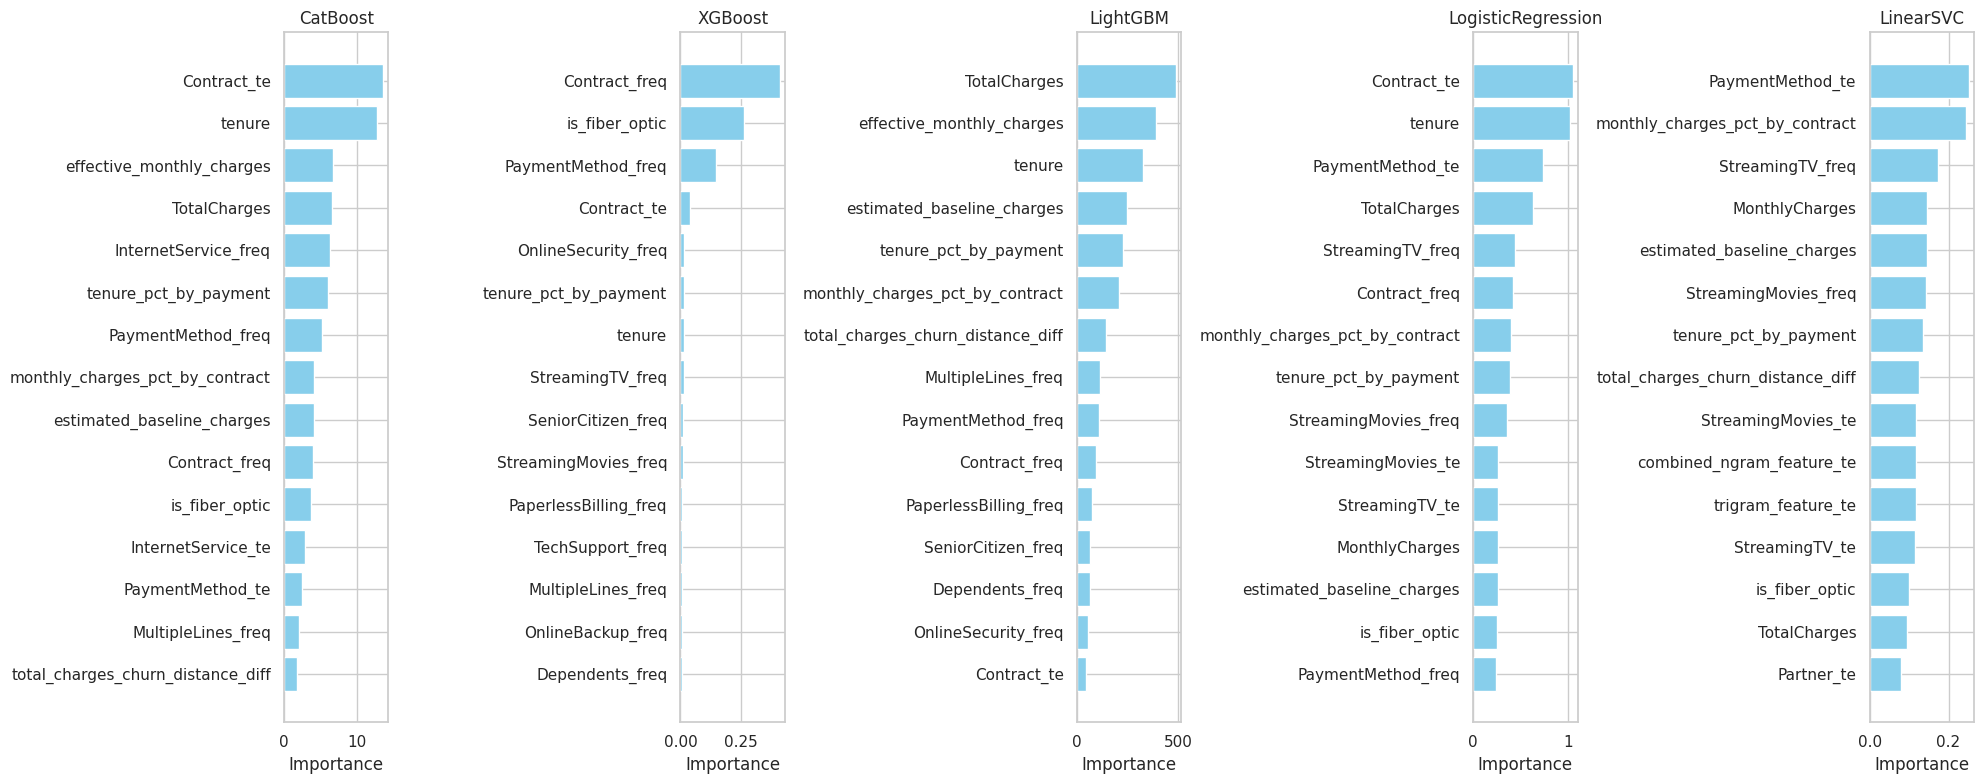

In [36]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# 1. 上位5モデルの定義
# ==========================================
top5_models = {
    "CatBoost": models["CatBoost"],
    "XGBoost": models["XGBoost"],
    "LightGBM": models["LightGBM"],
    "LogisticRegression": models["LogisticRegression"],
    "LinearSVC": models["LinearSVC"],
}

# 最終的な学習・予測全体を通じて各モデルの重要度を格納する辞書
feature_importances_dict = {name: np.zeros(len(current_features)) for name in top5_models.keys()}

# ==========================================
# 2. 5-fold CV 内で特徴量重要度を集計（平均を取るため）
# ==========================================
print("--- Calculating Feature Importances across Folds ---", flush=True)

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(train_df, train_df["Churn"])
):
    outer_train = train_df.iloc[train_idx].copy()
    outer_val = train_df.iloc[val_idx].copy()

    # 安全な型キャスト処理
    for col in outer_train.columns:
        is_category = outer_train[col].dtype.name == "category"
        is_not_encoded = col not in cat_cols_to_encode
        if is_category and is_not_encoded:
            outer_train[col] = outer_train[col].astype("float32", errors="ignore")
            outer_val[col] = outer_val[col].astype("float32", errors="ignore")

    outer_train_enc, outer_val_enc = apply_target_encoding(
        outer_train, outer_val, cat_cols_to_encode
    )

    te_cols = [f"{c}_te" for c in cat_cols_to_encode]
    current_features = [
        f for f in base_features if f not in cat_cols_to_encode
    ] + te_cols
    current_features = [
        f for f in current_features if f in outer_train_enc.columns
    ]

    X_train = outer_train_enc[current_features]
    y_train = outer_train_enc["Churn"]
    X_val = outer_val_enc[current_features]
    y_val = outer_val_enc["Churn"]

    for name, model in top5_models.items():
        clf = clone(model)

        # 線形モデルの場合はスケーリング必須
        if name in ["LogisticRegression", "LinearSVC"]:
            scaler = StandardScaler()
            X_train_processed = scaler.fit_transform(X_train)
            X_val_processed = scaler.transform(X_val)
        else:
            X_train_processed = X_train
            X_val_processed = X_val

        clf.fit(X_train_processed, y_train)

        # 重要度（または係数の絶対値）の取得
        if hasattr(clf, "feature_importances_"):
            imp = clf.feature_importances_
        elif hasattr(clf, "coef_"):
            # 線形モデルは係数の絶対値を利用
            imp = np.abs(clf.coef_[0])
        else:
            imp = np.zeros(X_train.shape[1])

        # 5フォールド分の平均を取るため加算
        feature_importances_dict[name] += imp / 5.0

# ==========================================
# 3. 結果をDataFrameにまとめて上位特徴量を表示
# ==========================================
importance_df = pd.DataFrame(feature_importances_dict, index=current_features)

print("\n--- Top 10 Features by Model (Importance / Abs Coef) ---")
for name in top5_models.keys():
    print(f"\n[{name} Top 10 Features]")
    sorted_imp = importance_df[name].sort_values(ascending=False).head(10)
    for feat, val in sorted_imp.items():
        print(f"  {feat:30s}: {val:.4f}")

# ==========================================
# 4. グラフによる可視化（上位15個をプロット）
# ==========================================
fig, axes = plt.subplots(1, len(top5_models), figsize=(20, 8), sharey=False)
axes = axes.flatten()

for i, (name, _) in enumerate(top5_models.items()):
    top_features = importance_df[name].sort_values(ascending=True).tail(15)
    axes[i].barh(top_features.index, top_features.values, color="skyblue")
    axes[i].set_title(f"{name}")
    axes[i].set_xlabel("Importance")

plt.tight_layout()
plt.show()

In [37]:
!pip install optuna -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 22.1 MB/s eta 0:00:00


In [38]:
import lightgbm as lgb
import numpy as np
import optuna
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

# Optunaの大量のログを非表示にする
optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial):
    """各試行（trial）でハイパーパラメータを変えて3-fold CVスコアを計算します。"""

    params = {
        "objective": "binary",
        "metric": "auc",
        "boosting_type": "gbdt",
        "random_state": 42,
        "verbose": -1,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }

    # 3-fold CV に変更して軽量化・高速化
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    fold_scores = []

    for train_idx, val_idx in inner_cv.split(train_df, train_df["Churn"]):
        outer_train = train_df.iloc[train_idx].copy()
        outer_val = train_df.iloc[val_idx].copy()

        # 安全な型キャスト処理
        for col in outer_train.columns:
            is_category = outer_train[col].dtype.name == "category"
            is_not_encoded = col not in cat_cols_to_encode
            if is_category and is_not_encoded:
                outer_train[col] = outer_train[col].astype(
                    "float32", errors="ignore"
                )
                outer_val[col] = outer_val[col].astype(
                    "float32", errors="ignore"
                )

        # ターゲットエンコーディングの適用
        outer_train_enc, outer_val_enc = apply_target_encoding(
            outer_train, outer_val, cat_cols_to_encode
        )

        te_cols = [f"{c}_te" for c in cat_cols_to_encode]
        current_features = [
            f for f in base_features if f not in cat_cols_to_encode
        ] + te_cols
        current_features = [
            f for f in current_features if f in outer_train_enc.columns
        ]

        X_train = outer_train_enc[current_features]
        y_train = outer_train_enc["Churn"]
        X_val = outer_val_enc[current_features]
        y_val = outer_val_enc["Churn"]

        model = lgb.LGBMClassifier(**params, n_estimators=1000)

        model.fit(
            X_train,
            y_train,
            eval_set=[(X_val, y_val)],
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
        )

        preds = model.predict_proba(X_val)[:, 1]
        score = roc_auc_score(y_val, preds)
        fold_scores.append(score)

    mean_score = np.mean(fold_scores)

    print(
        f"Trial {trial.number:2d} finished | Mean ROC-AUC (3-fold): {mean_score:.5f}",
        flush=True,
    )
    return mean_score


# ==========================================
# Optunaによる最適化の実行（n_trials=10）
# ==========================================
print("--- Starting Fast Optuna Tuning for LightGBM ---", flush=True)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10, timeout=None)

print("\n--- Best Hyperparameters ---")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

print(f"\nBest Mean ROC-AUC: {study.best_value:.4f}")

--- Starting Fast Optuna Tuning for LightGBM ---
Trial  0 finished | Mean ROC-AUC (3-fold): 0.91620
Trial  1 finished | Mean ROC-AUC (3-fold): 0.91610
Trial  2 finished | Mean ROC-AUC (3-fold): 0.91615
Trial  3 finished | Mean ROC-AUC (3-fold): 0.91605
Trial  4 finished | Mean ROC-AUC (3-fold): 0.91593
Trial  5 finished | Mean ROC-AUC (3-fold): 0.91442
Trial  6 finished | Mean ROC-AUC (3-fold): 0.91614
Trial  7 finished | Mean ROC-AUC (3-fold): 0.91594
Trial  8 finished | Mean ROC-AUC (3-fold): 0.91599
Trial  9 finished | Mean ROC-AUC (3-fold): 0.91592

--- Best Hyperparameters ---
  learning_rate: 0.04071017488057335
  num_leaves: 59
  max_depth: 7
  min_child_samples: 36
  subsample: 0.771577755355918
  colsample_bytree: 0.837024010887661
  reg_alpha: 3.8964144381974464
  reg_lambda: 0.003436474377434926

Best Mean ROC-AUC: 0.9162


In [39]:
from scipy.optimize import minimize
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
import xgboost as xgb
from catboost import CatBoostClassifier
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. 使用する5モデルの定義
# ==========================================
best_lgb_params = study.best_params
best_lgb_params.update({
    "objective": "binary",
    "metric": "auc",
    "boosting_type": "gbdt",
    "random_state": 42,
    "verbose": -1,
})

ensemble_models = {
    "LightGBM_Opt": lgb.LGBMClassifier(
        **best_lgb_params, n_estimators=1000
    ),
    "CatBoost": CatBoostClassifier(
        random_state=42, verbose=0
    ),
    "XGBoost": xgb.XGBClassifier(
        random_state=42, eval_metric="logloss"
    ),
    "LogisticRegression": LogisticRegression(
        random_state=42, max_iter=1000
    ),
    "LinearSVC": LinearSVC(
        random_state=42, max_iter=1000
    ),
}

scaling_needed = {"LogisticRegression", "LinearSVC"}

# ==========================================
# 2. Out-of-Fold (OOF) 予測の収集
# ==========================================
print(
    "--- Collecting OOF Predictions for Ensemble ---",
    flush=True,
)

outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)
oof_preds = {
    name: np.zeros(len(train_df))
    for name in ensemble_models.keys()
}
y_trues = np.zeros(len(train_df))

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(train_df, train_df["Churn"])
):
    print(f"Processing Fold {fold + 1}/5...", flush=True)

    outer_train = train_df.iloc[train_idx].copy()
    outer_val = train_df.iloc[val_idx].copy()

    # 安全な型キャスト処理
    for col in outer_train.columns:
        is_category = (
            outer_train[col].dtype.name == "category"
        )
        is_not_encoded = col not in cat_cols_to_encode
        if is_category and is_not_encoded:
            outer_train[col] = outer_train[col].astype(
                "float32", errors="ignore"
            )
            outer_val[col] = outer_val[col].astype(
                "float32", errors="ignore"
            )

    # ターゲットエンコーディング
    outer_train_enc, outer_val_enc = apply_target_encoding(
        outer_train, outer_val, cat_cols_to_encode
    )

    te_cols = [f"{c}_te" for c in cat_cols_to_encode]
    current_features = [
        f for f in base_features
        if f not in cat_cols_to_encode
    ] + te_cols
    current_features = [
        f for f in current_features
        if f in outer_train_enc.columns
    ]

    X_train = outer_train_enc[current_features]
    y_train = outer_train_enc["Churn"]
    X_val = outer_val_enc[current_features]
    y_val = outer_val_enc["Churn"]

    y_trues[val_idx] = y_val.values

    for name, model in ensemble_models.items():
        clf = clone(model)

        if name in scaling_needed:
            scaler = StandardScaler()
            X_tr_proc = scaler.fit_transform(X_train)
            X_va_proc = scaler.transform(X_val)
        else:
            X_tr_proc = X_train
            X_va_proc = X_val

        if name == "LightGBM_Opt":
            clf.fit(
                X_tr_proc,
                y_train,
                eval_set=[(X_va_proc, y_val)],
                callbacks=[
                    lgb.early_stopping(
                        stopping_rounds=50, verbose=False
                    )
                ],
            )
        else:
            clf.fit(X_tr_proc, y_train)

        if hasattr(clf, "predict_proba"):
            preds = clf.predict_proba(X_va_proc)[:, 1]
        else:
            decision = clf.decision_function(X_va_proc)
            preds = 1 / (1 + np.exp(-decision))

        oof_preds[name][val_idx] = preds

# ==========================================
# 3. 単体モデルの OOF ROC-AUC スコア評価
# ==========================================
print("\n--- Individual Model OOF ROC-AUC ---")
for name, preds in oof_preds.items():
    score = roc_auc_score(y_trues, preds)
    print(f"{name:20s}: {score:.5f}")

# ==========================================
# 4. アンサンブルの最適化（重み付き平均の探索）
# ==========================================
model_names = list(ensemble_models.keys())


def objective_weights(weights):
    w = np.array(weights)
    w = w / np.sum(w)

    blended_preds = np.zeros(len(y_trues))
    for i, name in enumerate(model_names):
        blended_preds += w[i] * oof_preds[name]

    return -roc_auc_score(y_trues, blended_preds)


init_weights = [1.0 / len(model_names)] * len(model_names)
bounds = [(0.0, 1.0)] * len(model_names)
constraints = ({
    "type": "eq",
    "fun": lambda w: 1 - sum(w),
})

result = minimize(
    objective_weights,
    init_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
)

best_weights = result.x / np.sum(result.x)

optimal_blend_preds = np.zeros(len(y_trues))
for i, name in enumerate(model_names):
    optimal_blend_preds += best_weights[i] * oof_preds[name]

optimal_blend_score = roc_auc_score(
    y_trues, optimal_blend_preds
)

print("\n--- Ensemble Results ---")
simple_avg_preds = np.mean(
    [oof_preds[n] for n in model_names], axis=0
)
print(
    "Simple Average Ensemble   : "
    f"{roc_auc_score(y_trues, simple_avg_preds):.5f}"
)
print(
    "Optimal Weighted Ensemble : "
    f"{optimal_blend_score:.5f}"
)

print("\nOptimal Weights for Each Model:")
for name, weight in zip(model_names, best_weights):
    print(f"  {name:20s}: {weight:.4f}")

--- Collecting OOF Predictions for Ensemble ---
Processing Fold 1/5...
Processing Fold 2/5...
Processing Fold 3/5...
Processing Fold 4/5...
Processing Fold 5/5...

--- Individual Model OOF ROC-AUC ---
LightGBM_Opt        : 0.91644
CatBoost            : 0.91616
XGBoost             : 0.91553
LogisticRegression  : 0.90884
LinearSVC           : 0.90638

--- Ensemble Results ---
Simple Average Ensemble   : 0.91561
Optimal Weighted Ensemble : 0.91561

Optimal Weights for Each Model:
  LightGBM_Opt        : 0.2000
  CatBoost            : 0.2000
  XGBoost             : 0.2000
  LogisticRegression  : 0.2000
  LinearSVC           : 0.2000


In [40]:
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

# ==========================================
# 1. テストデータの前提処理（訓練時と同様に実行）
# ==========================================
# ※もしテストデータに対する前処理セルがまだの場合は、
#   train_df 同様のフィーチャエンジニアリングを test_df にも適用してください。

print("--- Generating Test Predictions with 5-Fold Models ---", flush=True)

# テストデータ用の予測格納用配列
test_preds_dict = {name: np.zeros(len(test_df)) for name in ensemble_models.keys()}

# テストデータ側のベース特徴量
test_base_features = [
    f for f in base_features
    if f not in ["Churn", "customerID"] and f in test_df.columns
]

# ==========================================
# 2. 各 Fold の学習済みモデルでテストデータを予測
# ==========================================
for fold, (train_idx, val_idx) in enumerate(outer_cv.split(train_df, train_df["Churn"])):
    print(f"Inference using Fold {fold + 1}/5 models...", flush=True)

    outer_train = train_df.iloc[train_idx].copy()
    outer_val = train_df.iloc[val_idx].copy()

    # テストデータは毎回コピーして安全に処理
    current_test = test_df.copy()

    # 安全な型キャスト（訓練データ）
    for col in outer_train.columns:
        is_category = outer_train[col].dtype.name == "category"
        is_not_encoded = col not in cat_cols_to_encode
        if is_category and is_not_encoded:
            outer_train[col] = outer_train[col].astype(
                "float32", errors="ignore"
            )

    # 安全な型キャスト（テストデータ）
    for col in current_test.columns:
        is_category = current_test[col].dtype.name == "category"
        is_not_encoded = col not in cat_cols_to_encode
        if is_category and is_not_encoded:
            current_test[col] = current_test[col].astype(
                "float32", errors="ignore"
            )

    # ターゲットエンコーディング（テストには外側Train全体のマップを適用）
    # ※テストデータ専用のTE適用関数、または一括マップ適用を行ってください
    train_enc, _ = apply_target_encoding(
        outer_train, outer_val, cat_cols_to_encode
    )

    # テストデータへのTE適用ロジック
    test_enc = current_test.copy()
    for col in cat_cols_to_encode:
        target_name = f"{col}_te"
        tr_series = outer_train[col].astype(str)
        encoding_map = (
            pd.DataFrame({col: tr_series, "Churn": outer_train["Churn"]})
            .groupby(col)["Churn"]
            .mean()
            .to_dict()
        )
        test_enc[target_name] = (
            test_enc[col].astype(str)
            .map(encoding_map)
            .fillna(0.5)
            .astype("float32")
        )

    te_cols = [f"{c}_te" for c in cat_cols_to_encode]
    curr_features = [
        f for f in test_base_features if f not in cat_cols_to_encode
    ] + te_cols

    X_train = train_enc[curr_features]
    y_train = train_enc["Churn"]
    X_test = test_enc[curr_features]

    # 各モデルの学習とテスト予測（5foldの平均を取るため、各foldで予測して足し込む）
    # 各モデルの学習とテスト予測
    for name, model in ensemble_models.items():
        clf = clone(model)

        if name in scaling_needed:
            scaler = StandardScaler()
            X_tr_proc = scaler.fit_transform(X_train)
            X_te_proc = scaler.transform(X_test)
        else:
            X_tr_proc = X_train.values  # NumPy配列化して安全にする
            X_te_proc = X_test.values

        if name == "LightGBM_Opt":
            outer_val_enc, _ = apply_target_encoding(
                outer_val, outer_val, cat_cols_to_encode
            )

            if name in scaling_needed:
                X_val_proc = scaler.transform(
                    outer_val_enc[curr_features]
                )
            else:
                # 検証データも同様にNumPy配列に変換
                X_val_proc = outer_val_enc[curr_features].values

            clf.fit(
                X_tr_proc,
                y_train,
                eval_set=[(X_val_proc, outer_val["Churn"])],
                callbacks=[
                    lgb.early_stopping(
                        stopping_rounds=50, verbose=False
                    )
                ],
            )
        else:
            clf.fit(X_tr_proc, y_train)

        if hasattr(clf, "predict_proba"):
            fold_preds = clf.predict_proba(X_te_proc)[:, 1]
        else:
            decision = clf.decision_function(X_te_proc)
            fold_preds = 1 / (1 + np.exp(-decision))

        test_preds_dict[name] += fold_preds / 5.0

# ==========================================
# 3. 最適重み（Optimal Weights）によるブレンド
# ==========================================
final_test_preds = np.zeros(len(test_df))

for i, name in enumerate(model_names):
    final_test_preds += best_weights[i] * test_preds_dict[name]

# ==========================================
# 4. 提出用 CSV ファイルの作成（修正版）
# ==========================================
# あらかじめ退避してあった test_id をそのまま使用する
submission = pd.DataFrame({
    "id": test_id,
    "Churn": final_test_preds,
})

submission.to_csv(
    "submission_optimal_ensemble.csv", index=False
)

print("\n--- Submission File Created Successfully! ---")
print(submission.head())
print(f"\nTotal rows: {len(submission)}")

--- Generating Test Predictions with 5-Fold Models ---
Inference using Fold 1/5 models...
Inference using Fold 2/5 models...
Inference using Fold 3/5 models...
Inference using Fold 4/5 models...
Inference using Fold 5/5 models...

--- Submission File Created Successfully! ---
       id     Churn
0  594194  0.115038
1  594195  0.032449
2  594196  0.164647
3  594197  0.036034
4  594198  0.509569

Total rows: 254655
